# AQUA — Exploratory Data Analysis

## Research Objective

To investigate the distribution, variation, temporal patterns, and relationships among aquaculture water-quality measurements collected from fish ponds in India.

## Purpose of This Notebook

This notebook explores the audited AQUA dataset to:

1. Understand the distribution of water-quality measurements.
2. Examine differences between morning and evening observations.
3. Investigate temporal and regional patterns.
4. Explore variation between ponds and repeated observations.
5. Examine relationships between water-quality parameters and the recorded water-quality status.
6. Identify patterns, potential associations, and questions for subsequent statistical analysis.

## Methodological Considerations

The analysis will account for:

- Repeated measurements from individual ponds.
- Unequal observation frequencies across ponds.
- Missing and structurally unavailable measurements.
- Changes in ammonia measurement protocols.
- Changes in regional coverage over time.
- Potential measurement anomalies identified during the data-quality audit.
- The limitations of the recorded water-quality classification.

## Analytical Principle

Exploratory findings will be treated as descriptive evidence. Observed associations will not be interpreted as causal relationships.

No observations will be silently deleted, and transformations or exclusions will be documented.

## Expected Outcome

A clear understanding of the dataset's structure and major patterns to inform the statistical analysis and predictive-modelling methodology.

In [1]:
# CELL 1: DATASET PATH VERIFICATION

from pathlib import Path

current_directory = Path.cwd()
dataset_path = current_directory.parent / "data" / "raw" / "water_quality.csv"

print({
    "Notebook working directory": str(current_directory),
    "Expected dataset path": str(dataset_path),
    "Dataset exists": dataset_path.is_file(),
    "Dataset size (MB)": round(dataset_path.stat().st_size / (1024 ** 2), 2)
    if dataset_path.is_file() else None
})

{'Notebook working directory': 'c:\\Users\\hymar\\OneDrive\\Desktop\\AQUA-DS-2026\\notebooks', 'Expected dataset path': 'c:\\Users\\hymar\\OneDrive\\Desktop\\AQUA-DS-2026\\data\\raw\\water_quality.csv', 'Dataset exists': True, 'Dataset size (MB)': 3.14}


In [2]:
# CELL 2: LOAD AND VERIFY THE ORIGINAL DATASET

import pandas as pd

df = pd.read_csv(dataset_path)

verification = (
    f"Dataset loaded successfully\n"
    f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns\n"
    f"Unique columns: {df.columns.nunique()}\n"
    f"Duplicate rows: {df.duplicated().sum():,}\n"
    f"\nTarget distribution:\n"
    f"{df['Is WQ in range?'].value_counts(dropna=False).to_string()}"
)

print(verification)

Dataset loaded successfully
Shape: 12,431 rows × 53 columns
Unique columns: 53
Duplicate rows: 0

Target distribution:
Is WQ in range?
Yes    10064
No      2367


In [3]:
# CELL 3: CORE WATER-QUALITY DESCRIPTIVE STATISTICS

core_parameters = [
    "DO (mg/L)",
    "pH",
    "Temp (in °C)"
]

summary = (
    df[core_parameters]
    .describe()
    .T
    .reset_index()
    .rename(columns={"index": "Parameter"})
    .round(3)
)

print(summary.to_string(index=False))

   Parameter   count   mean   std   min   25%   50%  75%   max
   DO (mg/L) 12412.0  6.636 3.622  0.00  3.50  4.70 10.1 27.10
          pH 12412.0  8.216 0.276  5.52  8.06  8.25  8.4  9.54
Temp (in °C) 12410.0 29.503 2.441 21.40 27.80 29.80 31.2 37.80


FIGURE EXPORTED SUCCESSFULLY
Location: ..\outputs\figures\11_core_water_quality_distributions.png


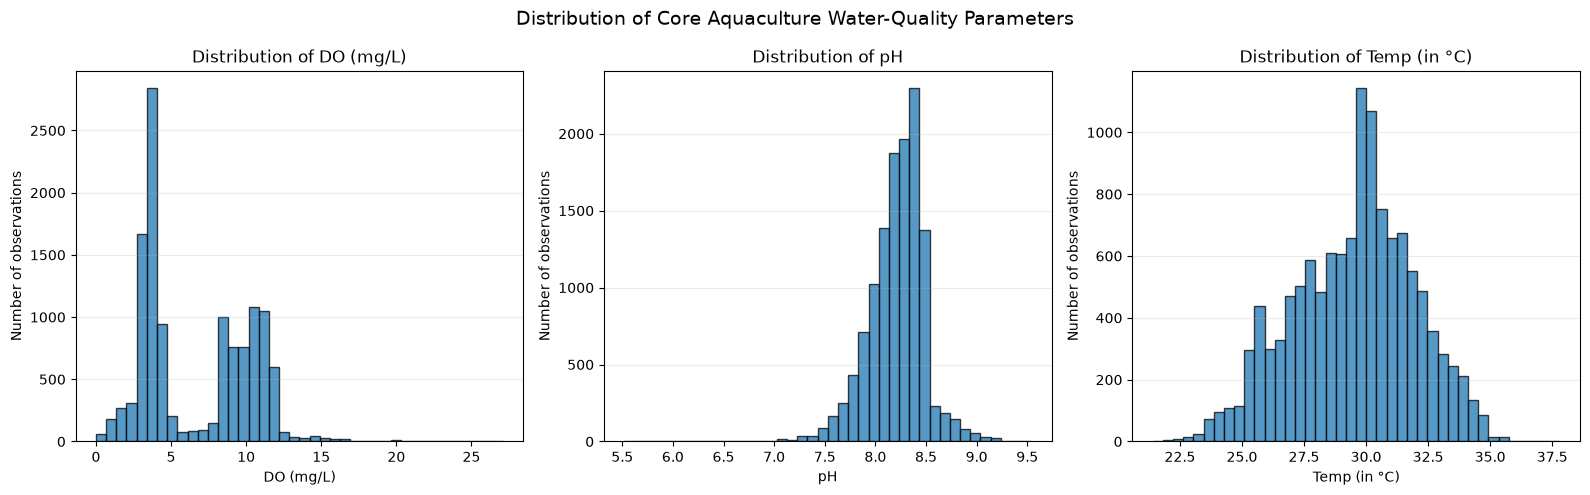

In [101]:
# CELL 4: CORE WATER-QUALITY DISTRIBUTION PLOTS

from pathlib import Path
import matplotlib.pyplot as plt

# Create figures directory
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

core_parameters = [
    "DO (mg/L)",
    "pH",
    "Temp (in °C)"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, parameter in zip(axes, core_parameters):

    values = df[parameter].dropna()

    ax.hist(
        values,
        bins=40,
        edgecolor="black",
        alpha=0.75
    )

    ax.set_title(f"Distribution of {parameter}")
    ax.set_xlabel(parameter)
    ax.set_ylabel("Number of observations")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Distribution of Core Aquaculture Water-Quality Parameters",
    fontsize=14
)

plt.tight_layout()

# Export high-resolution figure
figure_path = (
    figures_dir / "11_core_water_quality_distributions.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("FIGURE EXPORTED SUCCESSFULLY")
print("Location:", figure_path)

plt.show()

In [5]:
# CELL 5: CORE MEASUREMENTS BY OBSERVATION TYPE

parameters = ["DO (mg/L)", "pH", "Temp (in °C)"]

summary = (
    df.groupby("Type", dropna=False)[parameters]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)

print(summary.to_string())

        DO (mg/L)                          pH                      Temp (in °C)                      
            count    mean median    std count   mean median    std        count    mean median    std
Type                                                                                                 
Evening      5970  10.084  10.20  1.882  5970  8.354  8.380  0.219         5966  30.616   30.8  2.188
Morning      6440   3.439   3.50  0.868  6440  8.088  8.110  0.261         6442  28.473   28.8  2.199
NaN             2   7.350   7.35  1.626     2  8.515  8.515  0.163            2  28.900   28.9  0.424


FIGURE EXPORTED SUCCESSFULLY
Location: ..\outputs\figures\10_morning_vs_evening_distribution_comparison.png


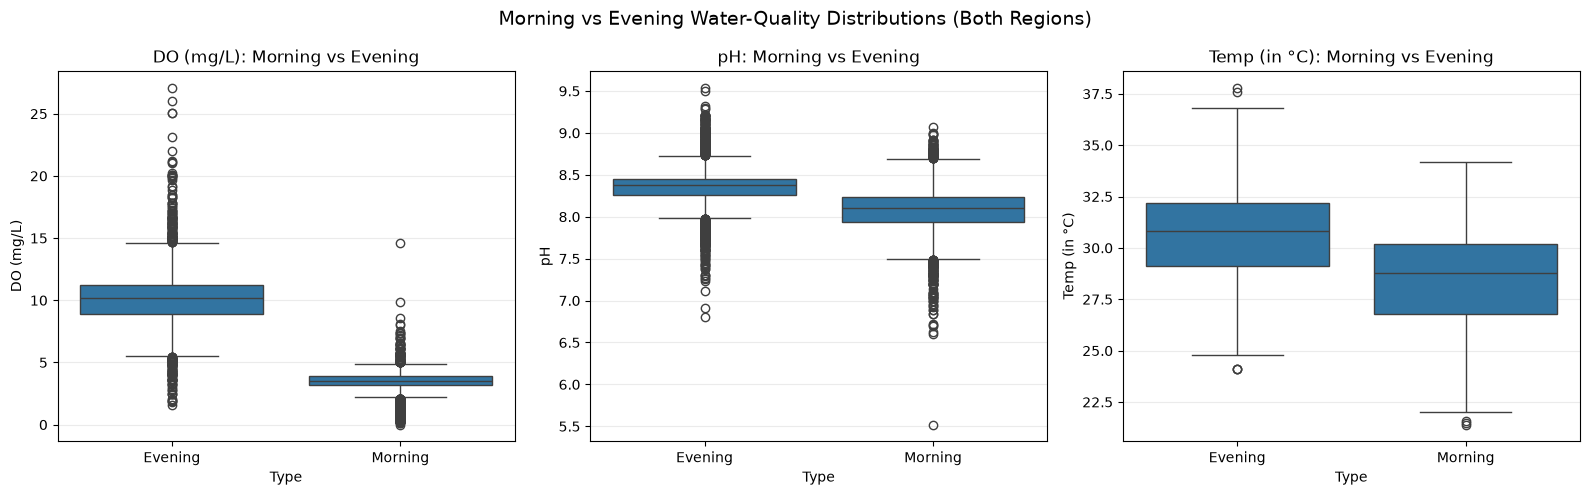

In [100]:
# CELL 6: MORNING VS EVENING DISTRIBUTION COMPARISON

from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

# Create figures directory
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

parameters = ["DO (mg/L)", "pH", "Temp (in °C)"]

comparison_data = df[
    df["Type"].isin(["Morning", "Evening"])
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, parameter in zip(axes, parameters):

    sns.boxplot(
        data=comparison_data,
        x="Type",
        y=parameter,
        ax=ax
    )

    ax.set_title(f"{parameter}: Morning vs Evening")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Morning vs Evening Water-Quality Distributions (Both Regions)",
    fontsize=14
)

plt.tight_layout()

# Export high-resolution figure
figure_path = (
    figures_dir / "10_morning_vs_evening_distribution_comparison.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("FIGURE EXPORTED SUCCESSFULLY")
print("Location:", figure_path)

plt.show()

In [7]:
# CELL 7: REGIONAL DISTRIBUTION OF CORE MEASUREMENTS

parameters = ["DO (mg/L)", "pH", "Temp (in °C)"]

regional_summary = (
    df.groupby("region")[parameters]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)

print(regional_summary.to_string())

        DO (mg/L)                         pH                      Temp (in °C)                      
            count   mean median    std count   mean median    std        count    mean median    std
region                                                                                              
Eluru        9238  6.678    4.6  3.762  9239  8.242   8.28  0.259         9229  29.264   29.5  2.545
Nellore      3174  6.513    4.9  3.177  3173  8.141   8.17  0.308         3181  30.197   30.3  1.954


In [8]:
# CELL 8: REGIONAL COMPARISON WITHIN OBSERVATION TYPE

parameters = ["DO (mg/L)", "pH", "Temp (in °C)"]

regional_type_summary = (
    df[df["Type"].isin(["Morning", "Evening"])]
    .groupby(["region", "Type"])[parameters]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)

print(regional_type_summary.to_string())

                DO (mg/L)                          pH                      Temp (in °C)                      
                    count    mean median    std count   mean median    std        count    mean median    std
region  Type                                                                                                 
Eluru   Evening      4402  10.319   10.5  1.891  4403  8.380   8.40  0.199         4396  30.424   30.5  2.273
        Morning      4836   3.364    3.4  0.852  4836  8.116   8.15  0.242         4833  28.210   28.4  2.309
Nellore Evening      1568   9.424    9.3  1.692  1567  8.280   8.30  0.254         1570  31.153   31.4  1.828
        Morning      1604   3.665    3.7  0.877  1604  8.004   8.03  0.295         1609  29.265   29.6  1.589


FIGURE EXPORTED SUCCESSFULLY
Location: ..\outputs\figures\09_regional_water_quality_distributions.png


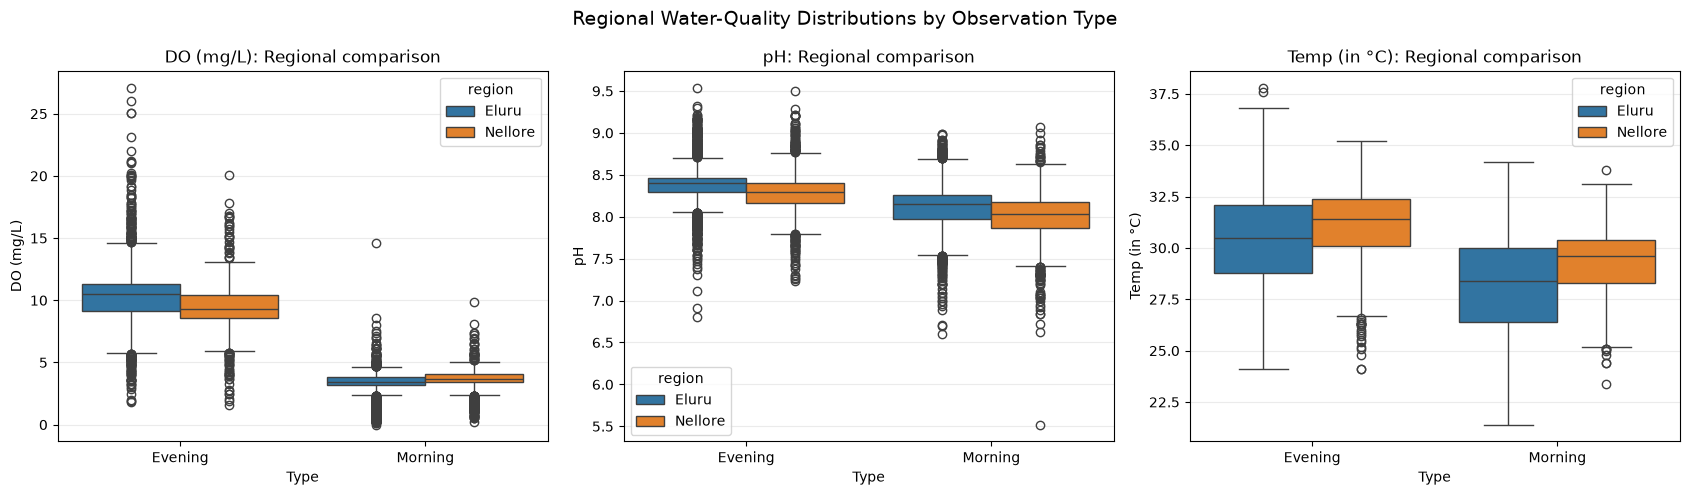

In [99]:
# CELL 9: REGIONAL DISTRIBUTIONS WITHIN MORNING AND EVENING GROUPS

from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

# Create figures directory
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

parameters = ["DO (mg/L)", "pH", "Temp (in °C)"]

comparison_data = df[
    df["Type"].isin(["Morning", "Evening"])
    & df["region"].isin(["Eluru", "Nellore"])
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, parameter in zip(axes, parameters):

    sns.boxplot(
        data=comparison_data,
        x="Type",
        y=parameter,
        hue="region",
        ax=ax
    )

    ax.set_title(f"{parameter}: Regional comparison")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Regional Water-Quality Distributions by Observation Type",
    fontsize=14
)

plt.tight_layout()

# Export high-resolution figure
figure_path = (
    figures_dir / "09_regional_water_quality_distributions.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("FIGURE EXPORTED SUCCESSFULLY")
print("Location:", figure_path)

plt.show()

In [10]:
# CELL 10: TARGET DISTRIBUTION BY REGION AND OBSERVATION TYPE

target_summary = (
    df.groupby(["region", "Type"], dropna=False)["Is WQ in range?"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("Percentage")
    .reset_index()
    .pivot(
        index=["region", "Type"],
        columns="Is WQ in range?",
        values="Percentage"
    )
    .round(2)
    .reset_index()
)

print(target_summary.to_string(index=False))

 region    Type     No   Yes
  Eluru Evening  16.44 83.56
  Eluru Morning  20.12 79.88
Nellore     NaN 100.00   NaN
Nellore Evening  22.52 77.48
Nellore Morning  19.39 80.61


In [11]:
# CELL 11: TARGET COUNTS BY REGION AND OBSERVATION TYPE

target_counts = (
    pd.crosstab(
        index=[df["region"], df["Type"]],
        columns=df["Is WQ in range?"],
        dropna=False
    )
    .reset_index()
)

print(target_counts.to_string(index=False))

 region    Type  No  Yes
  Eluru Evening 724 3679
  Eluru Morning 975 3870
  Eluru     NaN   0    0
Nellore Evening 354 1218
Nellore Morning 312 1297
Nellore     NaN   2    0


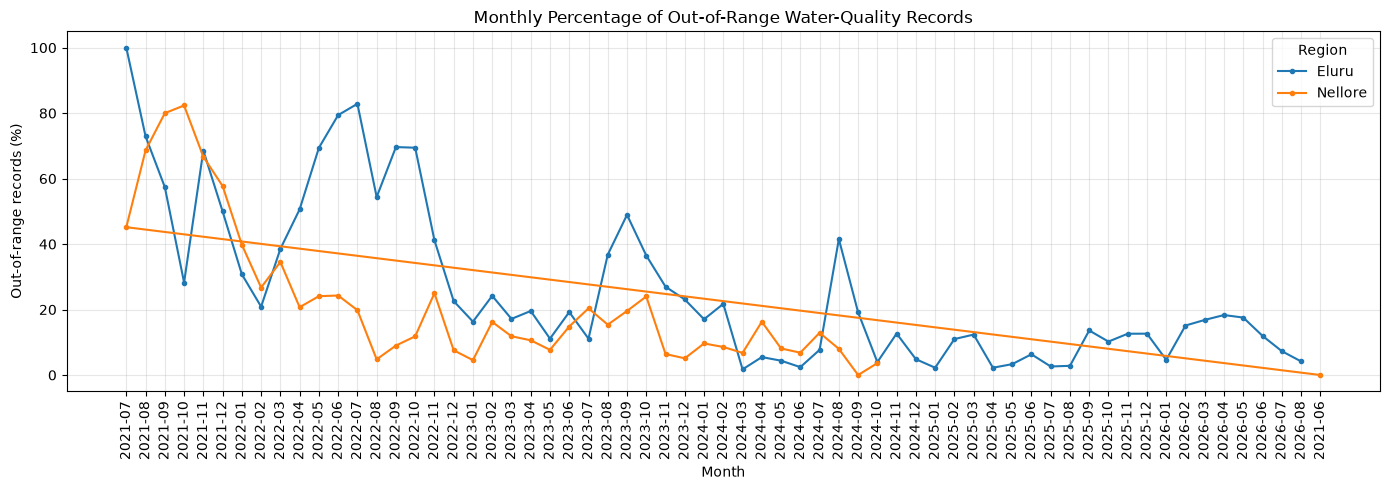

In [12]:
# CELL 12: MONTHLY WATER-QUALITY STATUS TRENDS

monthly_data = df.copy()

monthly_data["Date"] = pd.to_datetime(
    monthly_data["Date of data collection"],
    format="%m/%d/%Y",
    errors="coerce"
)

monthly_data["Month"] = monthly_data["Date"].dt.to_period("M")

monthly_summary = (
    monthly_data
    .dropna(subset=["Month", "region", "Is WQ in range?"])
    .groupby(["Month", "region"])
    .agg(
        Total=("Is WQ in range?", "size"),
        Out_of_range=("Is WQ in range?", lambda x: (x == "No").sum())
    )
    .reset_index()
)

monthly_summary["No_percentage"] = (
    monthly_summary["Out_of_range"] / monthly_summary["Total"] * 100
)

monthly_summary["Month"] = monthly_summary["Month"].astype(str)

fig, ax = plt.subplots(figsize=(14, 5))

for region, group in monthly_summary.groupby("region"):
    ax.plot(
        group["Month"],
        group["No_percentage"],
        marker="o",
        markersize=3,
        label=region
    )

ax.set_title("Monthly Percentage of Out-of-Range Water-Quality Records")
ax.set_xlabel("Month")
ax.set_ylabel("Out-of-range records (%)")
ax.legend(title="Region")
ax.grid(alpha=0.3)
ax.tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

FIGURE EXPORTED SUCCESSFULLY
Location: ..\outputs\figures\08_monthly_water_quality_status_trends.png


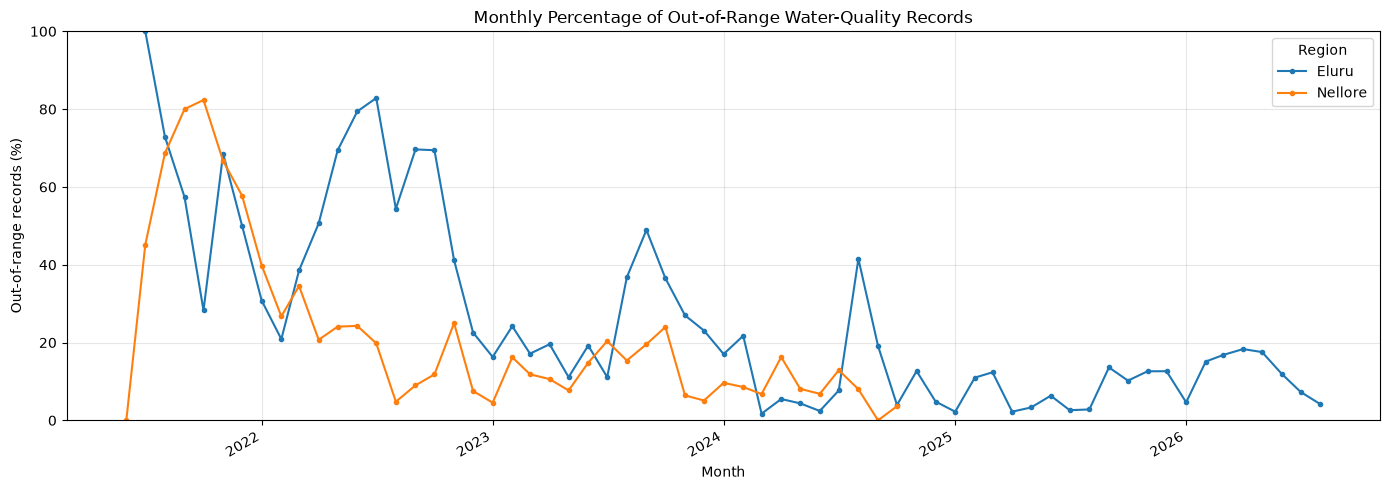

In [98]:
# CELL 13: MONTHLY WATER-QUALITY STATUS TRENDS
# Uses actual datetime values to ensure chronological alignment.

from pathlib import Path

# Create figures directory
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

monthly_data = df.copy()

monthly_data["Date"] = pd.to_datetime(
    monthly_data["Date of data collection"],
    format="%m/%d/%Y",
    errors="coerce"
)

monthly_data["Month"] = (
    monthly_data["Date"].dt.to_period("M").dt.to_timestamp()
)

monthly_summary = (
    monthly_data
    .dropna(subset=["Month", "region", "Is WQ in range?"])
    .groupby(["Month", "region"])
    .agg(
        Total=("Is WQ in range?", "size"),
        Out_of_range=("Is WQ in range?", lambda x: (x == "No").sum())
    )
    .reset_index()
)

monthly_summary["No_percentage"] = (
    monthly_summary["Out_of_range"]
    / monthly_summary["Total"] * 100
)

fig, ax = plt.subplots(figsize=(14, 5))

for region, group in monthly_summary.groupby("region"):

    group = group.sort_values("Month")

    ax.plot(
        group["Month"],
        group["No_percentage"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=region
    )

ax.set_title("Monthly Percentage of Out-of-Range Water-Quality Records")
ax.set_xlabel("Month")
ax.set_ylabel("Out-of-range records (%)")
ax.set_ylim(0, 100)
ax.legend(title="Region")
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()

# Export high-resolution figure
figure_path = (
    figures_dir / "08_monthly_water_quality_status_trends.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("FIGURE EXPORTED SUCCESSFULLY")
print("Location:", figure_path)

plt.show()

In [14]:
# CELL 14: MONTHLY REGIONAL SAMPLE SIZE AUDIT

monthly_counts = (
    monthly_data
    .dropna(subset=["Month", "region", "Is WQ in range?"])
    .groupby(["Month", "region"])
    .agg(
        Total_observations=("Is WQ in range?", "size"),
        Out_of_range=("Is WQ in range?", lambda x: (x == "No").sum())
    )
    .reset_index()
)

monthly_counts["No_percentage"] = (
    monthly_counts["Out_of_range"]
    / monthly_counts["Total_observations"] * 100
)

coverage_summary = (
    monthly_counts
    .groupby("region")
    .agg(
        First_month=("Month", "min"),
        Last_month=("Month", "max"),
        Months_with_data=("Month", "nunique"),
        Total_observations=("Total_observations", "sum"),
        Minimum_monthly_count=("Total_observations", "min"),
        Median_monthly_count=("Total_observations", "median"),
        Maximum_monthly_count=("Total_observations", "max")
    )
    .reset_index()
)

print(coverage_summary.to_string(index=False))

 region First_month Last_month  Months_with_data  Total_observations  Minimum_monthly_count  Median_monthly_count  Maximum_monthly_count
  Eluru  2021-07-01 2026-08-01                62                9248                     12                 121.0                    404
Nellore  2021-06-01 2024-10-01                41                3183                      2                  72.0                    167


In [15]:
# CELL 15: LOW MONTHLY SAMPLE SIZE INVESTIGATION

low_sample_months = (
    monthly_counts[
        monthly_counts["Total_observations"] < 20
    ]
    .sort_values(["region", "Month"])
    .copy()
)

low_sample_months["Month"] = (
    low_sample_months["Month"].dt.strftime("%Y-%m")
)

print(
    low_sample_months[
        ["region", "Month", "Total_observations",
         "Out_of_range", "No_percentage"]
    ].round(2).to_string(index=False)
)

 region   Month  Total_observations  Out_of_range  No_percentage
  Eluru 2021-07                  12            12          100.0
Nellore 2021-06                   2             0            0.0


In [16]:
# CELL 16: OVERALL TARGET DISTRIBUTION

target_distribution = (
    df["Is WQ in range?"]
    .value_counts(dropna=False)
    .rename_axis("Water_quality_status")
    .reset_index(name="Observations")
)

target_distribution["Percentage"] = (
    target_distribution["Observations"] / len(df) * 100
).round(2)

print(target_distribution.to_string(index=False))

Water_quality_status  Observations  Percentage
                 Yes         10064       80.96
                  No          2367       19.04


In [17]:
# CELL 17: DISSOLVED OXYGEN BY TARGET AND OBSERVATION TYPE

comparison_data = df[
    df["Type"].isin(["Morning", "Evening"])
    & df["Is WQ in range?"].isin(["Yes", "No"])
].copy()

do_summary = (
    comparison_data
    .groupby(["Type", "Is WQ in range?"])["DO (mg/L)"]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)

print(do_summary.to_string())

                         count    mean  median    std
Type    Is WQ in range?                              
Evening No                1078   9.953     9.4  3.681
        Yes               4892  10.113    10.3  1.155
Morning No                1287   2.562     2.4  1.407
        Yes               5153   3.658     3.5  0.456


FIGURE EXPORTED SUCCESSFULLY
Location: ..\outputs\figures\07_dissolved_oxygen_distribution_by_target.png


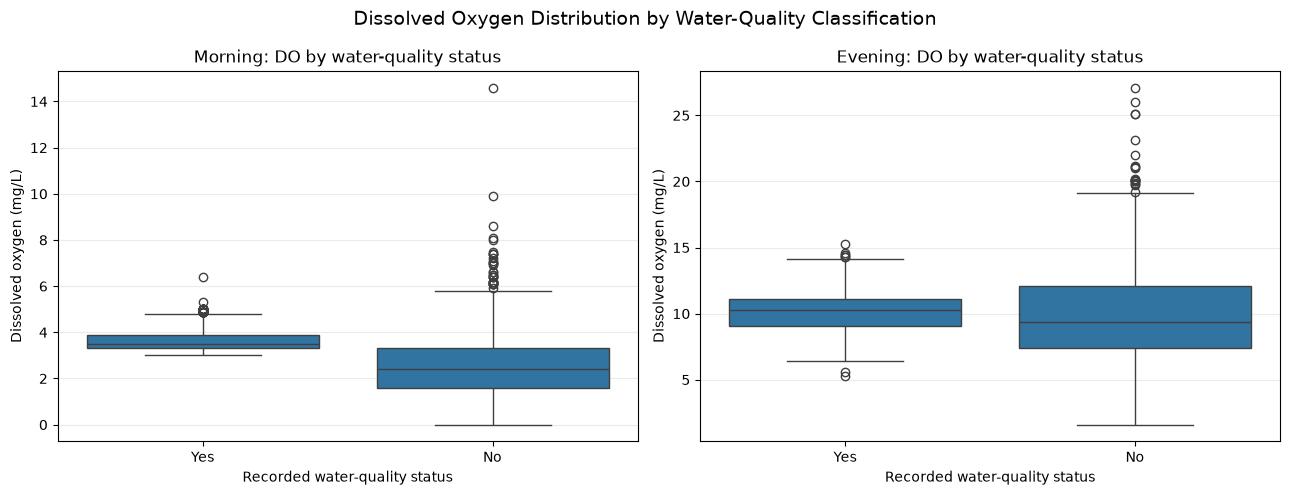

In [97]:
# CELL 18: DISSOLVED OXYGEN DISTRIBUTION BY TARGET

from pathlib import Path

# Create figures directory
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, observation_type in zip(axes, ["Morning", "Evening"]):

    subset = comparison_data[
        comparison_data["Type"] == observation_type
    ]

    sns.boxplot(
        data=subset,
        x="Is WQ in range?",
        y="DO (mg/L)",
        order=["Yes", "No"],
        ax=ax
    )

    ax.set_title(f"{observation_type}: DO by water-quality status")
    ax.set_xlabel("Recorded water-quality status")
    ax.set_ylabel("Dissolved oxygen (mg/L)")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Dissolved Oxygen Distribution by Water-Quality Classification",
    fontsize=14
)

plt.tight_layout()

# Export high-resolution figure
figure_path = (
    figures_dir / "07_dissolved_oxygen_distribution_by_target.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("FIGURE EXPORTED SUCCESSFULLY")
print("Location:", figure_path)

plt.show()

In [19]:
# CELL 19: pH BY TARGET AND OBSERVATION TYPE

ph_summary = (
    comparison_data
    .groupby(["Type", "Is WQ in range?"])["pH"]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)

print(ph_summary.to_string())

                         count   mean  median    std
Type    Is WQ in range?                             
Evening No                1077  8.495    8.51  0.358
        Yes               4893  8.323    8.37  0.158
Morning No                1287  8.175    8.18  0.354
        Yes               5153  8.066    8.10  0.227


FIGURE EXPORTED SUCCESSFULLY
Location: ..\outputs\figures\06_ph_distribution_by_target_and_observation_type.png


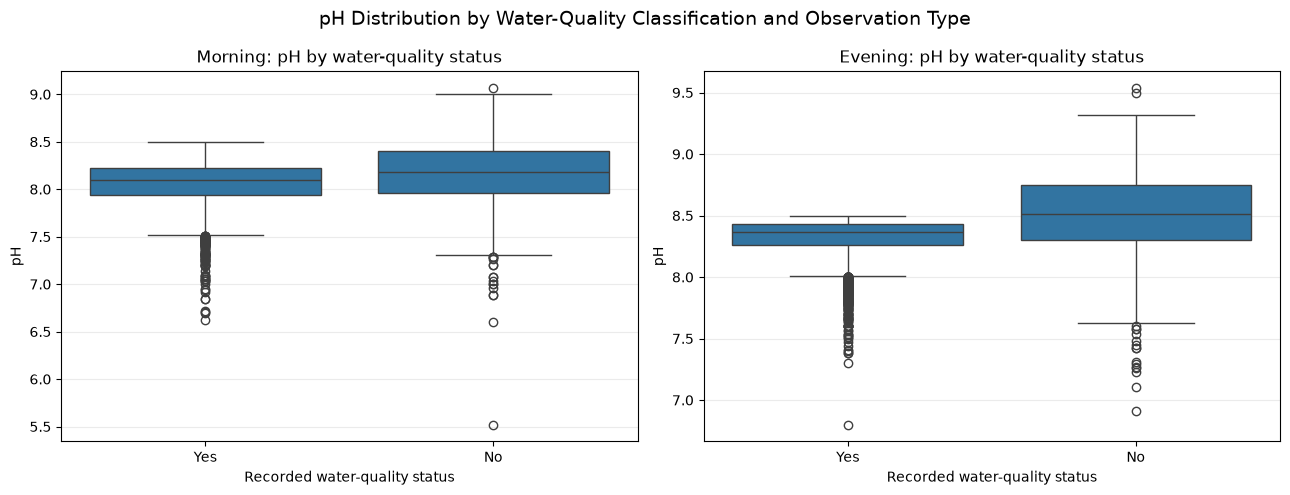

In [96]:
# CELL 20: pH DISTRIBUTION BY TARGET AND OBSERVATION TYPE

from pathlib import Path

# Create figures directory
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, observation_type in zip(axes, ["Morning", "Evening"]):

    subset = comparison_data[
        comparison_data["Type"] == observation_type
    ]

    sns.boxplot(
        data=subset,
        x="Is WQ in range?",
        y="pH",
        order=["Yes", "No"],
        ax=ax
    )

    ax.set_title(f"{observation_type}: pH by water-quality status")
    ax.set_xlabel("Recorded water-quality status")
    ax.set_ylabel("pH")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "pH Distribution by Water-Quality Classification and Observation Type",
    fontsize=14
)

plt.tight_layout()

# Export high-resolution figure
figure_path = (
    figures_dir / "06_ph_distribution_by_target_and_observation_type.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("FIGURE EXPORTED SUCCESSFULLY")
print("Location:", figure_path)

plt.show()

In [21]:
# CELL 21: TEMPERATURE BY TARGET AND OBSERVATION TYPE

temperature_summary = (
    comparison_data
    .groupby(["Type", "Is WQ in range?"])["Temp (in °C)"]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)

print(temperature_summary.to_string())

                         count    mean  median    std
Type    Is WQ in range?                              
Evening No                1076  30.861    31.1  2.123
        Yes               4890  30.562    30.7  2.199
Morning No                1286  28.720    29.0  2.021
        Yes               5156  28.412    28.7  2.238


FIGURE EXPORTED SUCCESSFULLY
Location: ..\outputs\figures\05_temperature_distribution_by_target.png


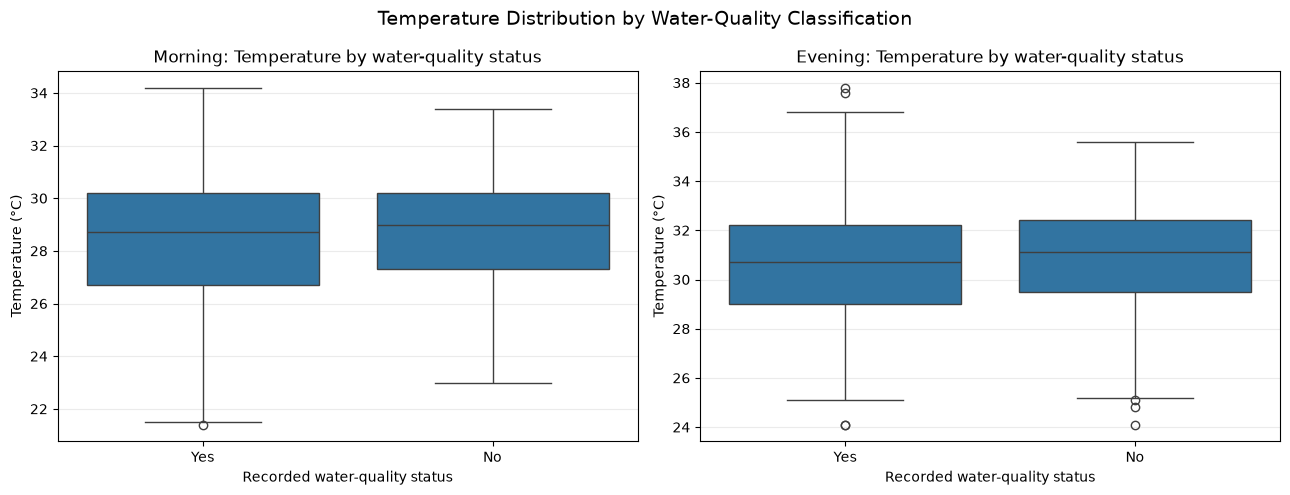

In [95]:
# CELL 22: TEMPERATURE DISTRIBUTION BY TARGET

from pathlib import Path

# Create figures directory
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, observation_type in zip(axes, ["Morning", "Evening"]):

    subset = comparison_data[
        comparison_data["Type"] == observation_type
    ]

    sns.boxplot(
        data=subset,
        x="Is WQ in range?",
        y="Temp (in °C)",
        order=["Yes", "No"],
        ax=ax
    )

    ax.set_title(
        f"{observation_type}: Temperature by water-quality status"
    )
    ax.set_xlabel("Recorded water-quality status")
    ax.set_ylabel("Temperature (°C)")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Temperature Distribution by Water-Quality Classification",
    fontsize=14
)

plt.tight_layout()

# Export high-resolution figure
figure_path = (
    figures_dir / "05_temperature_distribution_by_target.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("FIGURE EXPORTED SUCCESSFULLY")
print("Location:", figure_path)

plt.show()

In [23]:
# CELL 23: CORRELATION AMONG CORE WATER-QUALITY PARAMETERS

core_parameters = [
    "DO (mg/L)",
    "pH",
    "Temp (in °C)"
]

correlation_matrix = df[core_parameters].corr(method="pearson").round(3)

print(correlation_matrix.to_string())

              DO (mg/L)     pH  Temp (in °C)
DO (mg/L)         1.000  0.490         0.416
pH                0.490  1.000         0.331
Temp (in °C)      0.416  0.331         1.000


In [24]:
# CELL 24: CORRELATION BY OBSERVATION TYPE

core_parameters = [
    "DO (mg/L)",
    "pH",
    "Temp (in °C)"
]

for observation_type in ["Morning", "Evening"]:
    subset = df.loc[
        df["Type"] == observation_type,
        core_parameters
    ]

    correlation_matrix = subset.corr(method="pearson").round(3)

    print(f"\n{observation_type} correlation matrix:")
    print(correlation_matrix.to_string())


Morning correlation matrix:
              DO (mg/L)     pH  Temp (in °C)
DO (mg/L)         1.000 -0.083        -0.024
pH               -0.083  1.000         0.150
Temp (in °C)     -0.024  0.150         1.000

Evening correlation matrix:
              DO (mg/L)     pH  Temp (in °C)
DO (mg/L)         1.000  0.294         0.077
pH                0.294  1.000         0.157
Temp (in °C)      0.077  0.157         1.000


In [25]:
# CELL 25: CORRELATION BY REGION AND OBSERVATION TYPE

core_parameters = [
    "DO (mg/L)",
    "pH",
    "Temp (in °C)"
]

correlation_results = []

for (region, observation_type), group in df.groupby(
    ["region", "Type"],
    dropna=True
):
    correlations = group[core_parameters].corr(method="pearson")

    correlation_results.append({
        "Region": region,
        "Type": observation_type,
        "DO_pH": correlations.loc["DO (mg/L)", "pH"],
        "DO_Temperature": correlations.loc["DO (mg/L)", "Temp (in °C)"],
        "pH_Temperature": correlations.loc["pH", "Temp (in °C)"],
        "Observations": len(group)
    })

correlation_summary = pd.DataFrame(correlation_results)

print(correlation_summary.round(3).to_string(index=False))

 Region    Type  DO_pH  DO_Temperature  pH_Temperature  Observations
  Eluru Evening  0.261           0.115           0.203          4403
  Eluru Morning -0.061          -0.071           0.203          4845
Nellore Evening  0.280           0.099           0.178          1572
Nellore Morning -0.050          -0.000           0.195          1609


In [26]:
# CELL 26: PAIRWISE CORRELATION SAMPLE SIZE VERIFICATION

parameter_pairs = [
    ("DO (mg/L)", "pH"),
    ("DO (mg/L)", "Temp (in °C)"),
    ("pH", "Temp (in °C)")
]

pairwise_results = []

for (region, observation_type), group in df.groupby(
    ["region", "Type"],
    dropna=True
):
    for first, second in parameter_pairs:
        valid_pairs = group[[first, second]].dropna()

        pairwise_results.append({
            "Region": region,
            "Type": observation_type,
            "Parameter_pair": f"{first} vs {second}",
            "Valid_pairs": len(valid_pairs)
        })

pairwise_summary = pd.DataFrame(pairwise_results)

print(pairwise_summary.to_string(index=False))

 Region    Type            Parameter_pair  Valid_pairs
  Eluru Evening           DO (mg/L) vs pH         4402
  Eluru Evening DO (mg/L) vs Temp (in °C)         4395
  Eluru Evening        pH vs Temp (in °C)         4396
  Eluru Morning           DO (mg/L) vs pH         4836
  Eluru Morning DO (mg/L) vs Temp (in °C)         4833
  Eluru Morning        pH vs Temp (in °C)         4833
Nellore Evening           DO (mg/L) vs pH         1567
Nellore Evening DO (mg/L) vs Temp (in °C)         1566
Nellore Evening        pH vs Temp (in °C)         1566
Nellore Morning           DO (mg/L) vs pH         1604
Nellore Morning DO (mg/L) vs Temp (in °C)         1604
Nellore Morning        pH vs Temp (in °C)         1604


FIGURE EXPORTED SUCCESSFULLY
Location: ..\outputs\figures\04_regional_observation_type_correlation_heatmaps.png
Figure dimensions: [12.  9.]


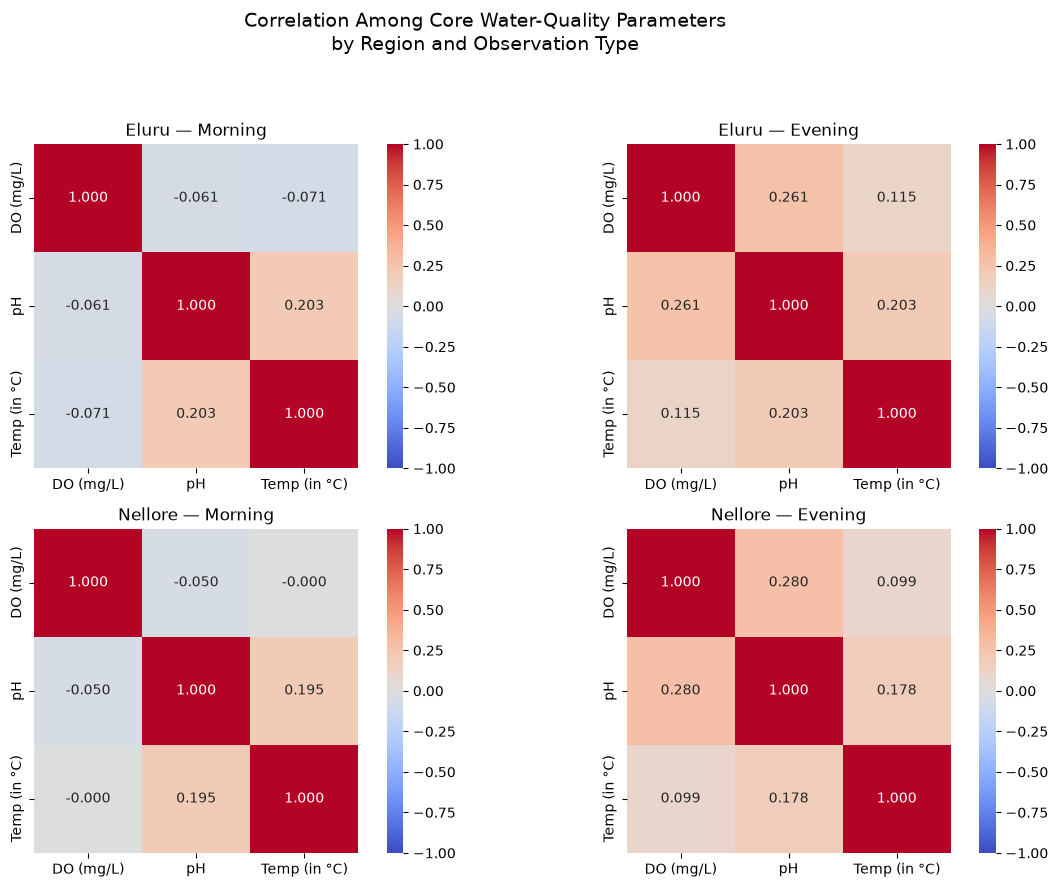

In [94]:
# CELL 27: REGION AND OBSERVATION-TYPE CORRELATION HEATMAPS

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Create figures directory
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

core_parameters = [
    "DO (mg/L)",
    "pH",
    "Temp (in °C)"
]

groups = [
    ("Eluru", "Morning"),
    ("Eluru", "Evening"),
    ("Nellore", "Morning"),
    ("Nellore", "Evening")
]

# Validate required columns
required_columns = ["region", "Type"] + core_parameters

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (region, observation_type) in zip(axes.flat, groups):

    subset = df[
        (df["region"] == region)
        & (df["Type"] == observation_type)
    ][core_parameters]

    if subset.dropna(how="all").empty:
        raise ValueError(
            f"No usable observations for {region} — {observation_type}"
        )

    correlation_matrix = subset.corr()

    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".3f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        ax=ax
    )

    ax.set_title(f"{region} — {observation_type}")

fig.suptitle(
    "Correlation Among Core Water-Quality Parameters\n"
    "by Region and Observation Type",
    fontsize=14
)

fig.tight_layout(rect=[0, 0, 1, 0.94])

# Export high-resolution figure
figure_path = (
    figures_dir
    / "04_regional_observation_type_correlation_heatmaps.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("FIGURE EXPORTED SUCCESSFULLY")
print("Location:", figure_path)
print("Figure dimensions:", fig.get_size_inches())

plt.show()

In [28]:
# CELL 28: WATER COLOUR COLUMN AND CATEGORY VERIFICATION

water_colour_column = [
    column for column in df.columns
    if "water color" in column.lower()
    or "water colour" in column.lower()
]

print({
    "Matching columns": water_colour_column,
    "Recorded categories": (
        df[water_colour_column[0]].value_counts(dropna=False).to_dict()
        if len(water_colour_column) == 1
        else "Column not uniquely identified"
    )
})

{'Matching columns': ['Water color'], 'Recorded categories': {'Dark green': 5517, 'Light green': 3086, 'Saturated green': 1672, 'Light brown': 895, nan: 859, 'Transparent': 340, 'Dark brown': 62}}


In [29]:
# CELL 29: WATER COLOUR BY RECORDED WATER-QUALITY STATUS

water_colour_summary = pd.crosstab(
    df["Water color"],
    df["Is WQ in range?"],
    margins=False
)

water_colour_summary["Total"] = water_colour_summary.sum(axis=1)

water_colour_percentages = (
    pd.crosstab(
        df["Water color"],
        df["Is WQ in range?"],
        normalize="index"
    ) * 100
).round(2)

water_colour_results = water_colour_summary.join(
    water_colour_percentages.add_suffix("_percentage")
)

print(water_colour_results.to_string())

Is WQ in range?   No   Yes  Total  No_percentage  Yes_percentage
Water color                                                     
Dark brown        23    39     62          37.10           62.90
Dark green       813  4704   5517          14.74           85.26
Light brown      210   685    895          23.46           76.54
Light green      669  2417   3086          21.68           78.32
Saturated green  249  1423   1672          14.89           85.11
Transparent       39   301    340          11.47           88.53


FIGURE EXPORTED SUCCESSFULLY
..\outputs\figures\03_water_colour_and_quality_status.png


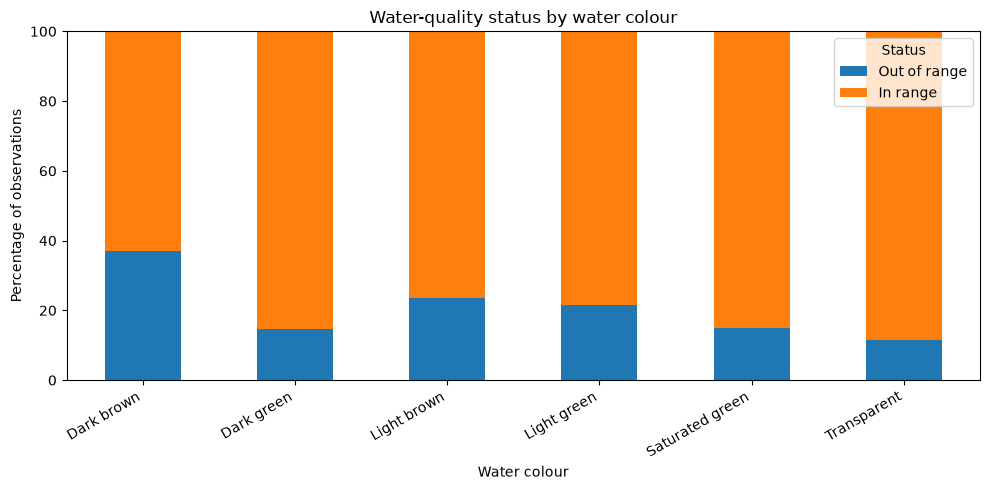

In [92]:
# CELL 30: WATER COLOUR AND WATER-QUALITY STATUS

from pathlib import Path

# Create figures directory
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plot_data = water_colour_percentages[["No", "Yes"]]

ax = plot_data.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    ylabel="Percentage of observations",
    xlabel="Water colour",
    title="Water-quality status by water colour",
    ylim=(0, 100)
)

ax.legend(
    ["Out of range", "In range"],
    title="Status"
)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

# Export high-resolution figure
figure_path = (
    figures_dir / "03_water_colour_and_quality_status.png"
)

ax.figure.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("FIGURE EXPORTED SUCCESSFULLY")
print(figure_path)

plt.show()

In [31]:
# CELL 31: WATER COLOUR AND TARGET BY REGION AND OBSERVATION TYPE

colour_target_counts = (
    df.dropna(subset=["Water color", "region", "Type"])
    .groupby(
        ["region", "Type", "Water color", "Is WQ in range?"],
        observed=True
    )
    .size()
    .unstack("Is WQ in range?", fill_value=0)
    .reindex(columns=["No", "Yes"], fill_value=0)
)

colour_target_summary = colour_target_counts.reset_index()
colour_target_summary["Total"] = (
    colour_target_summary["No"] + colour_target_summary["Yes"]
)
colour_target_summary["No_percentage"] = (
    colour_target_summary["No"]
    / colour_target_summary["Total"] * 100
).round(2)

print(colour_target_summary.to_string(index=False))

 region    Type     Water color  No  Yes  Total  No_percentage
  Eluru Evening      Dark brown   7   18     25          28.00
  Eluru Evening      Dark green 258 2100   2358          10.94
  Eluru Evening     Light brown  65  189    254          25.59
  Eluru Evening     Light green 197  548    745          26.44
  Eluru Evening Saturated green 111  688    799          13.89
  Eluru Evening     Transparent   0    2      2           0.00
  Eluru Morning      Dark brown  15   15     30          50.00
  Eluru Morning      Dark green 423 2215   2638          16.03
  Eluru Morning     Light brown  82  179    261          31.42
  Eluru Morning     Light green 257  646    903          28.46
  Eluru Morning Saturated green 138  735    873          15.81
  Eluru Morning     Transparent   0    3      3           0.00
Nellore Evening      Dark brown   0    3      3           0.00
Nellore Evening      Dark green  69  193    262          26.34
Nellore Evening     Light brown  35  151    186        

In [32]:
# CELL 32: WATER COLOUR AVAILABILITY BY REGION AND TYPE

colour_availability = (
    df.assign(
        Water_colour_missing=df["Water color"].isna()
    )
    .groupby(["region", "Type"], dropna=False)
    .agg(
        Total_observations=("Water color", "size"),
        Missing_colour=("Water_colour_missing", "sum")
    )
    .reset_index()
)

colour_availability["Missing_percentage"] = (
    colour_availability["Missing_colour"]
    / colour_availability["Total_observations"] * 100
).round(2)

print(colour_availability.to_string(index=False))

 region    Type  Total_observations  Missing_colour  Missing_percentage
  Eluru Evening                4403             220                5.00
  Eluru Morning                4845             137                2.83
Nellore Evening                1572             287               18.26
Nellore Morning                1609             214               13.30
Nellore     NaN                   2               1               50.00


In [33]:
# CELL 33: WATER COLOUR MISSINGNESS VERSUS TARGET DISTRIBUTION

missingness_summary = (
    df.assign(
        Colour_status=df["Water color"].isna().map({
            True: "Missing",
            False: "Recorded"
        })
    )
    .groupby(
        ["region", "Type", "Colour_status", "Is WQ in range?"],
        dropna=False
    )
    .size()
    .unstack("Is WQ in range?", fill_value=0)
    .reindex(columns=["No", "Yes"], fill_value=0)
    .reset_index()
)

missingness_summary["Total"] = (
    missingness_summary["No"] + missingness_summary["Yes"]
)

missingness_summary["No_percentage"] = (
    missingness_summary["No"]
    / missingness_summary["Total"] * 100
).round(2)

print(missingness_summary.to_string(index=False))

 region    Type Colour_status  No  Yes  Total  No_percentage
  Eluru Evening       Missing  86  134    220          39.09
  Eluru Evening      Recorded 638 3545   4183          15.25
  Eluru Morning       Missing  60   77    137          43.80
  Eluru Morning      Recorded 915 3793   4708          19.44
Nellore Evening       Missing 119  168    287          41.46
Nellore Evening      Recorded 235 1050   1285          18.29
Nellore Morning       Missing  98  116    214          45.79
Nellore Morning      Recorded 214 1181   1395          15.34
Nellore     NaN       Missing   1    0      1         100.00
Nellore     NaN      Recorded   1    0      1         100.00


In [34]:
# CELL 34: WEATHER COLUMN AND CATEGORY VERIFICATION

weather_columns = [
    column for column in df.columns
    if "weather" in column.lower()
]

print({
    "Matching columns": weather_columns,
    "Recorded categories": (
        df[weather_columns[0]].value_counts(dropna=False).to_dict()
        if len(weather_columns) == 1
        else "Column not uniquely identified"
    )
})

{'Matching columns': ['Weather'], 'Recorded categories': {'Sunny': 7500, nan: 728, 'Sunny, Cloud cover 50%': 662, 'Sunny, Cloud cover 75%': 624, 'Cloud cover 100%': 594, 'Foggy': 585, 'Sunny, Cloud cover 25%': 550, 'Cloud cover 50%': 303, 'Cloud cover 75%': 280, 'Sunny, Foggy': 277, 'Cloud cover 25%': 80, 'Rainy': 56, 'Cloud cover 100%, Foggy': 56, 'Sunny, Cloud cover 75%, Foggy': 42, 'Cloud cover 100%, Rainy': 32, 'Foggy, Sunny': 19, 'Cloud cover 50%, Sunny': 7, 'Sunny, Cloud cover 50%, Foggy': 5, 'Cloud cover 25%, Sunny': 4, 'Cloud cover 75%, Foggy': 3, 'Rainy, Foggy': 3, 'Cloud cover 50%, Rainy': 2, 'Cloud cover 25%, Foggy': 2, 'Cloud cover 50%, Foggy': 2, 'Cloud cover 25%, Cloud cover 50%': 2, 'Sunny, Cloud cover 100%': 2, 'Foggy, Cloud cover 25%': 1, 'Sunny, Rainy': 1, 'Cloud cover 75%, Sunny': 1, 'Rainy, Cloud cover 100%': 1, 'Cloud cover 50%, Cloud cover 100%': 1, 'Foggy, Sunny, Cloud cover 50%': 1, 'Cloud cover 25%, Cloud cover 75%': 1, 'Cloud cover 75%, Rainy': 1, 'Sunny, Clou

In [35]:
# CELL 35: WEATHER COMPONENT FREQUENCY AUDIT

weather_components = (
    df["Weather"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

component_summary = (
    weather_components
    .value_counts()
    .rename_axis("Weather component")
    .reset_index(name="Occurrences")
)

component_summary["Percentage_of_records"] = (
    component_summary["Occurrences"] / len(df) * 100
).round(2)

print(component_summary.to_string(index=False))

Weather component  Occurrences  Percentage_of_records
            Sunny         9697                  78.01
            Foggy          997                   8.02
  Cloud cover 50%          987                   7.94
  Cloud cover 75%          953                   7.67
 Cloud cover 100%          686                   5.52
  Cloud cover 25%          642                   5.16
            Rainy           96                   0.77


In [36]:
# CELL 36: WEATHER AVAILABILITY BY REGION AND TYPE

weather_availability = (
    df.assign(Weather_missing=df["Weather"].isna())
    .groupby(["region", "Type"], dropna=False)
    .agg(
        Total_observations=("Weather", "size"),
        Missing_weather=("Weather_missing", "sum")
    )
    .reset_index()
)

weather_availability["Missing_percentage"] = (
    weather_availability["Missing_weather"]
    / weather_availability["Total_observations"] * 100
).round(2)

print(weather_availability.to_string(index=False))

 region    Type  Total_observations  Missing_weather  Missing_percentage
  Eluru Evening                4403              166                3.77
  Eluru Morning                4845              183                3.78
Nellore Evening                1572              181               11.51
Nellore Morning                1609              196               12.18
Nellore     NaN                   2                2              100.00


In [37]:
# CELL 37: WEATHER MISSINGNESS VERSUS TARGET

weather_target_summary = (
    df.assign(
        Weather_status=df["Weather"].isna().map({
            True: "Missing",
            False: "Recorded"
        })
    )
    .groupby(
        ["region", "Type", "Weather_status", "Is WQ in range?"],
        dropna=False
    )
    .size()
    .unstack("Is WQ in range?", fill_value=0)
    .reindex(columns=["No", "Yes"], fill_value=0)
    .reset_index()
)

weather_target_summary["Total"] = (
    weather_target_summary["No"] + weather_target_summary["Yes"]
)

weather_target_summary["No_percentage"] = (
    weather_target_summary["No"]
    / weather_target_summary["Total"] * 100
).round(2)

print(weather_target_summary.to_string(index=False))

 region    Type Weather_status  No  Yes  Total  No_percentage
  Eluru Evening        Missing  92   74    166          55.42
  Eluru Evening       Recorded 632 3605   4237          14.92
  Eluru Morning        Missing  88   95    183          48.09
  Eluru Morning       Recorded 887 3775   4662          19.03
Nellore Evening        Missing 126   55    181          69.61
Nellore Evening       Recorded 228 1163   1391          16.39
Nellore Morning        Missing 119   77    196          60.71
Nellore Morning       Recorded 193 1220   1413          13.66
Nellore     NaN        Missing   2    0      2         100.00


In [38]:
# CELL 38: AMMONIA AVAILABILITY AUDIT

ammonia_columns = [
    "Ammonia—TAN (NH3-N) (mg/L)",
    "Ammonia—TAN (NH3) (mg/L)",
    "Ammonia—NH3 (mg/L)"
]

ammonia_availability = (
    df.groupby(["region", "Type"], dropna=False)
    .agg(
        Total_observations=("pond_id", "size"),
        **{
            f"{column}_available": (
                column,
                lambda values: values.notna().sum()
            )
            for column in ammonia_columns
        }
    )
    .reset_index()
)

print(ammonia_availability.to_string(index=False))

 region    Type  Total_observations  Ammonia—TAN (NH3-N) (mg/L)_available  Ammonia—TAN (NH3) (mg/L)_available  Ammonia—NH3 (mg/L)_available
  Eluru Evening                4403                                   202                                   0                             0
  Eluru Morning                4845                                  3097                                1659                          1660
Nellore Evening                1572                                   595                                   0                             0
Nellore Morning                1609                                  1396                                   0                             0
Nellore     NaN                   2                                     2                                   0                             0


In [39]:
# CELL 39: AMMONIA COLUMN OVERLAP AND DATE VERIFICATION

ammonia_columns = [
    "Ammonia—TAN (NH3-N) (mg/L)",
    "Ammonia—TAN (NH3) (mg/L)",
    "Ammonia—NH3 (mg/L)"
]

ammonia_presence = df[ammonia_columns].notna()

overlap_summary = (
    ammonia_presence.sum(axis=1)
    .value_counts()
    .sort_index()
    .rename_axis("Number_of_ammonia_columns_populated")
    .reset_index(name="Records")
)

date_summary = []

for column in ammonia_columns:
    available = df.loc[df[column].notna(), "Date of data collection"]

    date_summary.append({
        "Ammonia_column": column,
        "Records": len(available),
        "Earliest_date": available.min(),
        "Latest_date": available.max()
    })

print("ROW-LEVEL AMMONIA OVERLAP")
print(overlap_summary.to_string(index=False))

print("\nDATE COVERAGE BY AMMONIA COLUMN")
print(pd.DataFrame(date_summary).to_string(index=False))

ROW-LEVEL AMMONIA OVERLAP
 Number_of_ammonia_columns_populated  Records
                                   0     5481
                                   1     5290
                                   2     1659
                                   3        1

DATE COVERAGE BY AMMONIA COLUMN
            Ammonia_column  Records Earliest_date Latest_date
Ammonia—TAN (NH3-N) (mg/L)     5292    01/02/2024  12/31/2024
  Ammonia—TAN (NH3) (mg/L)     1659    01/02/2026  12/31/2025
        Ammonia—NH3 (mg/L)     1660    01/02/2026  12/31/2025


In [40]:
# RE-EDITED VERSION OF CELL 39,----39A
# CELL 40: AMMONIA OVERLAP AND CHRONOLOGICAL DATE VERIFICATION

ammonia_columns = [
    "Ammonia—TAN (NH3-N) (mg/L)",
    "Ammonia—TAN (NH3) (mg/L)",
    "Ammonia—NH3 (mg/L)"
]

# Identify the exact ammonia-column combinations
presence = df[ammonia_columns].notna()

combination_summary = (
    presence.astype(str)
    .agg(" | ".join, axis=1)
    .value_counts()
    .rename_axis("Ammonia_column_combination")
    .reset_index(name="Records")
)

# Parse collection dates chronologically
parsed_dates = pd.to_datetime(
    df["Date of data collection"].astype(str).str.strip(),
    format="%m/%d/%Y",
    errors="coerce"
)

date_summary = []

for column in ammonia_columns:
    mask = df[column].notna()
    valid_dates = parsed_dates[mask].dropna()

    date_summary.append({
        "Ammonia_column": column,
        "Records": int(mask.sum()),
        "Earliest_date": valid_dates.min().date() if not valid_dates.empty else None,
        "Latest_date": valid_dates.max().date() if not valid_dates.empty else None,
        "Unparsed_dates": int(mask.sum() - len(valid_dates))
    })

print("EXACT AMMONIA COLUMN COMBINATIONS")
print(combination_summary.to_string(index=False))

print("\nCHRONOLOGICAL DATE COVERAGE")
print(pd.DataFrame(date_summary).to_string(index=False))

EXACT AMMONIA COLUMN COMBINATIONS
Ammonia_column_combination  Records
     False | False | False     5481
      True | False | False     5290
       False | True | True     1658
        True | True | True        1
       True | False | True        1

CHRONOLOGICAL DATE COVERAGE
            Ammonia_column  Records Earliest_date Latest_date  Unparsed_dates
Ammonia—TAN (NH3-N) (mg/L)     5292    2021-06-19  2025-08-19               0
  Ammonia—TAN (NH3) (mg/L)     1659    2025-08-01  2026-08-06               0
        Ammonia—NH3 (mg/L)     1660    2025-07-31  2026-08-06               0


In [41]:
# CELL 41: INSPECT AMMONIA TRANSITION OVERLAP RECORDS

ammonia_columns = [
    "Ammonia—TAN (NH3-N) (mg/L)",
    "Ammonia—TAN (NH3) (mg/L)",
    "Ammonia—NH3 (mg/L)"
]

presence = df[ammonia_columns].notna()

unusual_overlap = df.loc[
    presence.sum(axis=1) == 3
    | (
        presence[ammonia_columns[0]]
        & ~presence[ammonia_columns[1]]
        & presence[ammonia_columns[2]]
    ),
    [
        "pond_id",
        "Date of data collection",
        "Type",
        "region",
        *ammonia_columns,
        "Is WQ in range?"
    ]
]

print(unusual_overlap.to_string(index=False))

      pond_id Date of data collection    Type  region  Ammonia—TAN (NH3-N) (mg/L)  Ammonia—TAN (NH3) (mg/L)  Ammonia—NH3 (mg/L) Is WQ in range?
ara2_10a5f8e4              08/19/2025 Morning   Eluru                        0.00                       NaN                 NaN             Yes
ara2_176528d3              08/19/2025 Morning   Eluru                        0.25                       NaN                 NaN             Yes
ara2_3a8fffae              08/19/2025 Morning   Eluru                        0.25                       NaN                 NaN             Yes
ara2_45e1cde5              08/19/2025 Morning   Eluru                        0.00                       NaN                 NaN             Yes
ara2_b3d128ac              08/19/2025 Morning   Eluru                        0.25                       NaN                 NaN             Yes
ara2_27b80a16              08/18/2025 Morning   Eluru                        0.25                       NaN                 NaN         

In [42]:
# RE-EDITED VERSION OF CELL 41
# CELL 42: CORRECTLY FILTER AND EXPORT EXCEPTIONAL AMMONIA OVERLAP RECORDS

ammonia_columns = [
    "Ammonia—TAN (NH3-N) (mg/L)",
    "Ammonia—TAN (NH3) (mg/L)",
    "Ammonia—NH3 (mg/L)"
]

presence = df[ammonia_columns].notna()

# Identify only the two exceptional combinations:
# 1. All three ammonia columns populated.
# 2. Old TAN-N and new NH3 populated, but transitional TAN missing.

mask = (
    (presence.sum(axis=1) == 3)
    |
    (
        presence[ammonia_columns[0]]
        & ~presence[ammonia_columns[1]]
        & presence[ammonia_columns[2]]
    )
)

output_columns = [
    "pond_id",
    "Date of data collection",
    "Type",
    "region",
    *ammonia_columns,
    "Is WQ in range?"
]

unusual_overlap = df.loc[mask, output_columns].copy()

output_path = "../outputs/tables/ammonia_overlap_exceptions.csv"

unusual_overlap.to_csv(output_path, index=False)

print(f"Exceptional records identified: {len(unusual_overlap)}")
print(f"File saved to: {output_path}")
print("\nEXCEPTIONAL AMMONIA OVERLAP RECORDS")
display(unusual_overlap)

Exceptional records identified: 2
File saved to: ../outputs/tables/ammonia_overlap_exceptions.csv

EXCEPTIONAL AMMONIA OVERLAP RECORDS


,pond_id,Date of data collection,Type,region,Ammonia—TAN (NH3-N) (mg/L),Ammonia—TAN (NH3) (mg/L),Ammonia—NH3 (mg/L),Is WQ in range?
3244,ara2_c15dc3a2,08/01/2025,Morning,Eluru,0.25,0.3,0.02,Yes
3262,ara2_32b91757,07/31/2025,Morning,Eluru,0.25,NaN,0.00,Yes


In [43]:
# CELL 43: INSPECT COMPLETE ORIGINAL AMMONIA EXCEPTION RECORDS

exception_indices = unusual_overlap.index

exception_records = df.loc[exception_indices].copy()

print("COMPLETE ORIGINAL RECORDS FOR THE TWO AMMONIA EXCEPTIONS")
print(f"Records inspected: {len(exception_records)}")
print(f"Columns available: {len(exception_records.columns)}")

display(exception_records.T)

COMPLETE ORIGINAL RECORDS FOR THE TWO AMMONIA EXCEPTIONS
Records inspected: 2
Columns available: 53


,3244,3262
pond_id,ara2_c15dc3a2,ara2_32b91757
region,Eluru,Eluru
Date of data collection,08/01/2025,07/31/2025
Time of data collection,07:06,06:45
Type,Morning,Morning
Is follow up,No,No
Is follow up possible,NaN,NaN
Reason follow up not possible,NaN,NaN
Group,Regular ara pond,Focus group new
Pond status,Treatment,Treatment


In [44]:
# CELL 44: FOCUSED INSPECTION OF AMMONIA EXCEPTION RECORDS

relevant_columns = [
    "pond_id",
    "Date of data collection",
    "Type",
    "region",
    "Ammonia—TAN (NH3-N) (mg/L)",
    "Ammonia—TAN (NH3) (mg/L)",
    "Ammonia—NH3 (mg/L)",
    "Dissolved oxygen (mg/L)",
    "pH",
    "Temperature (°C)",
    "Parameters out of range",
    "Notes",
    "Is WQ in range?"
]

# Retain only columns that actually exist in the dataset
available_columns = [
    col for col in relevant_columns if col in df.columns
]

display(
    df.loc[unusual_overlap.index, available_columns]
    .reset_index(drop=True)
)

,pond_id,Date of data collection,Type,region,Ammonia—TAN (NH3-N) (mg/L),Ammonia—TAN (NH3) (mg/L),Ammonia—NH3 (mg/L),pH,Parameters out of range,Notes,Is WQ in range?
0,ara2_c15dc3a2,08/01/2025,Morning,Eluru,0.25,0.3,0.02,7.88,NaN,NaN,Yes
1,ara2_32b91757,07/31/2025,Morning,Eluru,0.25,NaN,0.00,8.20,NaN,NaN,Yes


In [45]:
# CELL 45: AMMONIA DISTRIBUTION BY PROTOCOL, REGION AND OBSERVATION TYPE

ammonia_columns = [
    "Ammonia—TAN (NH3-N) (mg/L)",
    "Ammonia—TAN (NH3) (mg/L)",
    "Ammonia—NH3 (mg/L)"
]

group_columns = ["region", "Type"]

ammonia_long = df.melt(
    id_vars=group_columns,
    value_vars=ammonia_columns,
    var_name="Ammonia protocol",
    value_name="Ammonia value (mg/L)"
)

ammonia_summary = (
    ammonia_long
    .dropna(subset=["Ammonia value (mg/L)"])
    .groupby(
        ["Ammonia protocol", "region", "Type"],
        observed=True
    )["Ammonia value (mg/L)"]
    .agg(
        Sample_count="count",
        Mean="mean",
        Median="median",
        Minimum="min",
        Maximum="max"
    )
    .round(3)
    .reset_index()
)

display(ammonia_summary)

,Ammonia protocol,region,Type,Sample_count,Mean,Median,Minimum,Maximum
0,Ammonia—NH3 (mg/L),Eluru,Morning,1660,0.016,0.01,0.0,0.33
1,Ammonia—TAN (NH3) (mg/L),Eluru,Morning,1659,0.165,0.25,0.0,2.00
2,Ammonia—TAN (NH3-N) (mg/L),Eluru,Evening,202,0.337,0.20,0.0,2.00
3,Ammonia—TAN (NH3-N) (mg/L),Eluru,Morning,3097,0.221,0.21,0.0,3.00
4,Ammonia—TAN (NH3-N) (mg/L),Nellore,Evening,595,0.062,0.01,0.0,1.52
5,Ammonia—TAN (NH3-N) (mg/L),Nellore,Morning,1396,0.071,0.03,0.0,2.53


In [46]:
# CELL 46: PROTOCOL-SPECIFIC AMMONIA THRESHOLD ASSESSMENT

thresholds = {
    "Ammonia—TAN (NH3-N) (mg/L)": 0.5,
    "Ammonia—NH3 (mg/L)": 0.05
}

results = []

for column, threshold in thresholds.items():

    valid = df[column].notna()

    for (region, observation_type), group in df.loc[valid].groupby(
        ["region", "Type"],
        observed=True
    ):

        values = group[column]

        results.append({
            "Ammonia protocol": column,
            "Region": region,
            "Type": observation_type,
            "Threshold (mg/L)": threshold,
            "Sample count": len(values),
            "Below threshold": (values < threshold).sum(),
            "At or above threshold": (values >= threshold).sum(),
            "At or above threshold (%)": round(
                (values >= threshold).mean() * 100, 2
            )
        })

threshold_summary = pd.DataFrame(results)

display(threshold_summary)

,Ammonia protocol,Region,Type,Threshold (mg/L),Sample count,Below threshold,At or above threshold,At or above threshold (%)
0,Ammonia—TAN (NH3-N) (mg/L),Eluru,Evening,0.50,202,152,50,24.75
1,Ammonia—TAN (NH3-N) (mg/L),Eluru,Morning,0.50,3097,2991,106,3.42
2,Ammonia—TAN (NH3-N) (mg/L),Nellore,Evening,0.50,595,592,3,0.50
3,Ammonia—TAN (NH3-N) (mg/L),Nellore,Morning,0.50,1396,1387,9,0.64
4,Ammonia—NH3 (mg/L),Eluru,Morning,0.05,1660,1579,81,4.88


In [47]:
# CELL 47: INSPECT AMMONIA THRESHOLD EXCEEDANCE RECORDS

date_column = "Date of data collection"

old_tan = "Ammonia—TAN (NH3-N) (mg/L)"
new_nh3 = "Ammonia—NH3 (mg/L)"

old_exceedances = df.loc[
    df[old_tan] >= 0.5,
    ["pond_id", date_column, "region", "Type", old_tan,
     "Is WQ in range?"]
].copy()

new_exceedances = df.loc[
    df[new_nh3] >= 0.05,
    ["pond_id", date_column, "region", "Type", new_nh3,
     "Is WQ in range?"]
].copy()

old_exceedances["Protocol"] = "Old TAN-N"
new_exceedances["Protocol"] = "New NH3"

exceedance_records = pd.concat(
    [old_exceedances, new_exceedances],
    ignore_index=True
)

print(f"Old TAN-N exceedance records: {len(old_exceedances)}")
print(f"New NH3 exceedance records: {len(new_exceedances)}")

print("\nTOP 10 OLD TAN-N EXCEEDANCES")
display(
    old_exceedances
    .sort_values(old_tan, ascending=False)
    .head(10)
)

print("\nTOP 10 NEW NH3 EXCEEDANCES")
display(
    new_exceedances
    .sort_values(new_nh3, ascending=False)
    .head(10)
)

Old TAN-N exceedance records: 168
New NH3 exceedance records: 81

TOP 10 OLD TAN-N EXCEEDANCES


,pond_id,Date of data collection,region,Type,Ammonia—TAN (NH3-N) (mg/L),Is WQ in range?,Protocol
3660,ara2_6857ac3f,06/05/2025,Eluru,Morning,3.00,No,Old TAN-N
9414,ara2_84b6fb93,01/25/2023,Eluru,Morning,3.00,No,Old TAN-N
8648,ara2_84b6fb93,06/21/2023,Eluru,Morning,2.92,No,Old TAN-N
3700,ara2_c3cfe293,06/02/2025,Eluru,Morning,2.57,No,Old TAN-N
9105,ara2_c5671cf4,03/16/2023,Nellore,Morning,2.53,No,Old TAN-N
5669,ara2_7bd7da7f,10/04/2024,Eluru,Morning,2.12,No,Old TAN-N
11477,ara2_9eefff29,02/11/2022,Eluru,Morning,2.02,No,Old TAN-N
12353,ara2_bd32b7fb,08/17/2021,Eluru,Morning,2.00,No,Old TAN-N
12348,ara2_bd32b7fb,08/17/2021,Eluru,Evening,2.00,No,Old TAN-N
3529,ara2_29c9448f,06/19/2025,Eluru,Morning,1.87,No,Old TAN-N



TOP 10 NEW NH3 EXCEEDANCES


,pond_id,Date of data collection,region,Type,Ammonia—NH3 (mg/L),Is WQ in range?,Protocol
105,ara2_b001208b,07/15/2026,Eluru,Morning,0.33,No,New NH3
142,ara2_84b6fb93,07/10/2026,Eluru,Morning,0.26,No,New NH3
1596,ara2_6ca69422,02/23/2026,Eluru,Morning,0.21,No,New NH3
2494,ara2_95c4b2c4,11/08/2025,Eluru,Morning,0.20,No,New NH3
2562,ara2_249e0180,11/03/2025,Eluru,Morning,0.20,No,New NH3
1245,ara2_f17bbe2f,03/23/2026,Eluru,Morning,0.19,No,New NH3
2776,ara2_1fcb01f6,09/30/2025,Eluru,Morning,0.19,No,New NH3
1202,ara2_f17bbe2f,03/26/2026,Eluru,Morning,0.19,No,New NH3
1605,ara2_6ca69422,02/22/2026,Eluru,Morning,0.18,No,New NH3
2778,ara2_d54330d5,09/30/2025,Eluru,Morning,0.18,No,New NH3


In [48]:
# CELL 48: AMMONIA EXCEEDANCE AND TARGET CLASSIFICATION COMPARISON

old_tan = "Ammonia—TAN (NH3-N) (mg/L)"
new_nh3 = "Ammonia—NH3 (mg/L)"

exceedance_data = []

protocol_checks = [
    (old_tan, 0.5, "Old TAN-N"),
    (new_nh3, 0.05, "New NH3")
]

for column, threshold, protocol in protocol_checks:

    subset = df.loc[
        df[column].notna() & (df[column] >= threshold)
    ].copy()

    summary = (
        subset.groupby(
            ["region", "Type", "Is WQ in range?"],
            observed=True
        )
        .size()
        .reset_index(name="Record count")
    )

    summary.insert(0, "Protocol", protocol)
    exceedance_data.append(summary)

target_comparison = pd.concat(
    exceedance_data,
    ignore_index=True
)

display(target_comparison)

,Protocol,region,Type,Is WQ in range?,Record count
0,Old TAN-N,Eluru,Evening,No,50
1,Old TAN-N,Eluru,Morning,No,106
2,Old TAN-N,Nellore,Evening,No,3
3,Old TAN-N,Nellore,Morning,No,9
4,New NH3,Eluru,Morning,No,73
5,New NH3,Eluru,Morning,Yes,8


In [49]:
# CELL 49: INVESTIGATE NEW NH3 EXCEEDANCES CLASSIFIED AS WATER QUALITY IN RANGE

new_nh3 = "Ammonia—NH3 (mg/L)"

exception_records = df.loc[
    df[new_nh3].notna()
    & (df[new_nh3] >= 0.05)
    & (df["Is WQ in range?"] == "Yes")
].copy()

inspection_columns = [
    "pond_id",
    "Date of data collection",
    "Type",
    "region",
    new_nh3,
    "Dissolved oxygen (mg/L)",
    "pH",
    "Temperature (°C)",
    "Parameters out of range",
    "Notes",
    "Is WQ in range?"
]

available_columns = [
    col for col in inspection_columns if col in df.columns
]

print(f"Records requiring investigation: {len(exception_records)}")

display(
    exception_records[available_columns]
    .reset_index(drop=True)
)

Records requiring investigation: 8


,pond_id,Date of data collection,Type,region,Ammonia—NH3 (mg/L),pH,Parameters out of range,Notes,Is WQ in range?
0,ara2_8ee1e5e2,07/31/2026,Morning,Eluru,0.05,8.23,NaN,NaN,Yes
1,ara2_e985ca4a,07/09/2026,Morning,Eluru,0.05,8.17,NaN,NaN,Yes
2,ara2_7a7eace1,06/17/2026,Morning,Eluru,0.05,8.48,NaN,Evening data was not collected because of hot ...,Yes
3,ara2_725e7f3b,04/14/2026,Morning,Eluru,0.05,8.10,NaN,NaN,Yes
4,ara2_c4b7f174,04/08/2026,Morning,Eluru,0.05,8.16,NaN,NaN,Yes
5,ara2_e985ca4a,03/26/2026,Morning,Eluru,0.05,8.19,NaN,NaN,Yes
6,ara2_970ce848,03/11/2026,Morning,Eluru,0.05,8.24,NaN,NaN,Yes
7,ara2_e985ca4a,02/23/2026,Morning,Eluru,0.05,8.23,NaN,NaN,Yes


In [50]:
# RE-EDITED VERSION OF CELL 50
# CELL 51: NEW NH3 THRESHOLD-BOUNDARY INVESTIGATION

new_nh3 = "Ammonia—NH3 (mg/L)"

valid = df[new_nh3].notna()

ammonia_values = df.loc[valid, new_nh3]

boundary_data = df.loc[valid].copy()

boundary_data["Threshold_category"] = "Above 0.05"

boundary_data.loc[
    ammonia_values < 0.05, "Threshold_category"
] = "Below 0.05"

boundary_data.loc[
    ammonia_values == 0.05, "Threshold_category"
] = "Exactly 0.05"

boundary_summary = (
    boundary_data
    .groupby(
        ["Threshold_category", "Is WQ in range?"],
        observed=True
    )
    .size()
    .unstack(fill_value=0)
)

display(boundary_summary)

Is WQ in range?,No,Yes
Threshold_category,,
Above 0.05,62,0
Below 0.05,172,1407
Exactly 0.05,11,8


In [51]:
# CELL 52: INSPECT NEW NH3 THRESHOLD-BOUNDARY RECORDS

new_nh3 = "Ammonia—NH3 (mg/L)"

boundary_records = df.loc[
    df[new_nh3].eq(0.05)
].copy()

inspection_columns = [
    "pond_id",
    "Date of data collection",
    "Region",
    "Type",
    "Is WQ in range?",
    "Dissolved Oxygen (mg/L)",
    "pH",
    "Water temperature (°C)",
    "Ammonia—TAN (NH3) (mg/L)",
    "Weather",
    "Water colour",
    "Notes",
    "Parameters out of range"
]

available_columns = [
    col for col in inspection_columns
    if col in boundary_records.columns
]

boundary_records = boundary_records[available_columns].sort_values(
    by=["Is WQ in range?", "Date of data collection"],
    ascending=[True, True]
)

print("NH3 THRESHOLD-BOUNDARY RECORDS")
print(f"Total records: {len(boundary_records)}")
print("\nCLASSIFICATION COUNTS")
display(boundary_records["Is WQ in range?"].value_counts().to_frame("Record count"))

print("\nRECORD-LEVEL COMPARISON")
display(boundary_records)

NH3 THRESHOLD-BOUNDARY RECORDS
Total records: 19

CLASSIFICATION COUNTS


,Record count
Is WQ in range?,
No,11
Yes,8



RECORD-LEVEL COMPARISON


,pond_id,Date of data collection,Type,Is WQ in range?,pH,Ammonia—TAN (NH3) (mg/L),Weather,Notes,Parameters out of range
1486,ara2_29660d32,03/04/2026,Morning,No,8.23,0.50,Sunny,NaN,Dissolved Oxygen
1472,ara2_29660d32,03/05/2026,Morning,No,8.23,0.50,Sunny,NaN,Dissolved Oxygen
1182,ara2_6ca69422,03/27/2026,Morning,No,8.52,0.25,Sunny,NaN,"Dissolved Oxygen, Ph"
1170,ara2_6ca69422,03/28/2026,Morning,No,8.55,0.25,Sunny,NaN,"Dissolved Oxygen, Ph"
1068,ara2_4f79fc8d,04/07/2026,Morning,No,8.47,0.25,Sunny,NaN,Dissolved Oxygen
1069,ara2_6ca69422,04/07/2026,Morning,No,8.47,0.25,Sunny,NaN,Dissolved Oxygen
1015,ara2_6ca69422,04/09/2026,Morning,No,8.52,0.25,Sunny,NaN,"Dissolved Oxygen, Ph"
997,ara2_6ca69422,04/10/2026,Morning,No,8.51,0.25,Sunny,NaN,"Dissolved Oxygen, Ph"
671,ara2_00793177,05/06/2026,Morning,No,8.55,0.25,Cloud cover 50%,NaN,Ph
606,ara2_00793177,05/09/2026,Morning,No,8.53,0.25,Sunny,NaN,"Dissolved Oxygen, Ph"


In [52]:
# CELL 54: VERIFY NOTEBOOK STATE AND ACTUAL DATASET COLUMNS

if "df" not in globals():
    print("VERIFICATION FAILED: DataFrame 'df' is not available.")
else:
    relevant_terms = [
        "pond", "date", "region", "type", "dissolved oxygen",
        "ph", "temperature", "ammonia", "weather",
        "colour", "color", "notes", "parameters out of range",
        "is wq in range"
    ]

    matching_columns = [
        col for col in df.columns
        if any(term in str(col).lower() for term in relevant_terms)
    ]

    output = [
        "AQUA NOTEBOOK STATE VERIFICATION",
        "=" * 45,
        f"DataFrame shape: {df.shape}",
        f"Total columns: {len(df.columns)}",
        f"Cell 51 boundary summary available: {'boundary_summary' in globals()}",
        f"Cell 51 boundary records available: {'boundary_data' in globals()}",
        "",
        "EXACT MATCHING DATASET COLUMN NAMES",
        "-" * 45
    ]

    output.extend(f"{i}. {col}" for i, col in enumerate(matching_columns, 1))

    print("\n".join(output))

AQUA NOTEBOOK STATE VERIFICATION
DataFrame shape: (12431, 53)
Total columns: 53
Cell 51 boundary summary available: True
Cell 51 boundary records available: True

EXACT MATCHING DATASET COLUMN NAMES
---------------------------------------------
1. pond_id
2. region
3. Date of data collection
4. Type
5. Pond status
6. Weather
7. pH
8. Ammonia—TAN (NH3-N) (mg/L)
9. Ammonia—TAN (NH3) (mg/L)
10. Ammonia—NH3 (mg/L)
11. Water color
12. Is WQ in range?
13. Parameters out of range
14. Corrective actions implementation date
15. Corrective action notes
16. Notes (mortalities)
17. Self-initiated corrective actions implemented on (exact date)
18. Self-initiated corrective actions implemented (date range)
19. Self-initiated corrective actions notes
20. Notes


In [53]:
# CELL 55: INSPECT NEW NH3 THRESHOLD-BOUNDARY RECORDS

new_nh3 = "Ammonia—NH3 (mg/L)"

inspection_columns = [
    "pond_id",
    "Date of data collection",
    "region",
    "Type",
    "Is WQ in range?",
    "Ammonia—TAN (NH3) (mg/L)",
    "Weather",
    "Water color",
    "Corrective action notes",
    "Notes (mortalities)",
    "Notes",
    "Parameters out of range"
]

boundary_records = df.loc[
    df[new_nh3].eq(0.05),
    inspection_columns
].sort_values(
    by=["Is WQ in range?", "Date of data collection"]
).reset_index(drop=True)

display(boundary_records)

,pond_id,Date of data collection,region,Type,Is WQ in range?,Ammonia—TAN (NH3) (mg/L),Weather,Water color,Corrective action notes,Notes (mortalities),Notes,Parameters out of range
0,ara2_29660d32,03/04/2026,Eluru,Morning,No,0.50,Sunny,Saturated green,NaN,NaN,NaN,Dissolved Oxygen
1,ara2_29660d32,03/05/2026,Eluru,Morning,No,0.50,Sunny,Saturated green,NaN,NaN,NaN,Dissolved Oxygen
2,ara2_6ca69422,03/27/2026,Eluru,Morning,No,0.25,Sunny,Saturated green,NaN,NaN,NaN,"Dissolved Oxygen, Ph"
3,ara2_6ca69422,03/28/2026,Eluru,Morning,No,0.25,Sunny,Saturated green,NaN,NaN,NaN,"Dissolved Oxygen, Ph"
4,ara2_4f79fc8d,04/07/2026,Eluru,Morning,No,0.25,Sunny,Dark green,NaN,NaN,NaN,Dissolved Oxygen
5,ara2_6ca69422,04/07/2026,Eluru,Morning,No,0.25,Sunny,Saturated green,NaN,NaN,NaN,Dissolved Oxygen
6,ara2_6ca69422,04/09/2026,Eluru,Morning,No,0.25,Sunny,Saturated green,NaN,NaN,NaN,"Dissolved Oxygen, Ph"
7,ara2_6ca69422,04/10/2026,Eluru,Morning,No,0.25,Sunny,Saturated green,NaN,NaN,NaN,"Dissolved Oxygen, Ph"
8,ara2_00793177,05/06/2026,Eluru,Morning,No,0.25,Cloud cover 50%,Dark green,NaN,NaN,NaN,Ph
9,ara2_00793177,05/09/2026,Eluru,Morning,No,0.25,Sunny,Dark green,NaN,NaN,NaN,"Dissolved Oxygen, Ph"


In [54]:
# CELL 56: COMPARE CORE MEASUREMENTS AT THE NH3 THRESHOLD BOUNDARY

new_nh3 = "Ammonia—NH3 (mg/L)"

boundary_data = df.loc[
    df[new_nh3].eq(0.05)
].copy()

comparison_columns = [
    "Dissolved oxygen (mg/L)",
    "pH",
    "Water temperature (°C)"
]

available_columns = [
    col for col in comparison_columns
    if col in boundary_data.columns
]

summary = (
    boundary_data
    .groupby("Is WQ in range?")[available_columns]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)

display(summary)

pH                          
                count   mean median   min   max
Is WQ in range?                                
No                 11  8.484   8.52  8.23  8.74
Yes                 8  8.225   8.21  8.10  8.48

In [55]:
# CELL 57: INSPECT PH VALUES AT THE NH3 THRESHOLD BOUNDARY

new_nh3 = "Ammonia—NH3 (mg/L)"

boundary_ph_records = df.loc[
    df[new_nh3].eq(0.05),
    [
        "pond_id",
        "Date of data collection",
        "pH",
        "Is WQ in range?",
        "Parameters out of range"
    ]
].copy()

boundary_ph_records["pH above 8.5"] = (
    boundary_ph_records["pH"] > 8.5
)

boundary_ph_records = boundary_ph_records.sort_values(
    by=["Is WQ in range?", "pH"],
    ascending=[True, True]
).reset_index(drop=True)

display(boundary_ph_records)

,pond_id,Date of data collection,pH,Is WQ in range?,Parameters out of range,pH above 8.5
0,ara2_29660d32,03/05/2026,8.23,No,Dissolved Oxygen,False
1,ara2_29660d32,03/04/2026,8.23,No,Dissolved Oxygen,False
2,ara2_4f79fc8d,04/07/2026,8.47,No,Dissolved Oxygen,False
3,ara2_6ca69422,04/07/2026,8.47,No,Dissolved Oxygen,False
4,ara2_6ca69422,04/10/2026,8.51,No,"Dissolved Oxygen, Ph",True
5,ara2_6ca69422,04/09/2026,8.52,No,"Dissolved Oxygen, Ph",True
6,ara2_6ca69422,03/27/2026,8.52,No,"Dissolved Oxygen, Ph",True
7,ara2_00793177,05/09/2026,8.53,No,"Dissolved Oxygen, Ph",True
8,ara2_00793177,05/06/2026,8.55,No,Ph,True
9,ara2_6ca69422,03/28/2026,8.55,No,"Dissolved Oxygen, Ph",True


In [56]:
# CELL 58: IDENTIFY DISSOLVED OXYGEN COLUMN

do_columns = [
    col for col in df.columns
    if "oxygen" in str(col).lower()
    or str(col).lower().strip() in ["do", "do (mg/l)"]
]

print("DISSOLVED OXYGEN COLUMN VERIFICATION")
print("=" * 45)
print(f"Matching columns: {len(do_columns)}")

for col in do_columns:
    print(f"- {col}")

DISSOLVED OXYGEN COLUMN VERIFICATION
Matching columns: 1
- DO (mg/L)


In [57]:
# CELL 59: COMPARE DISSOLVED OXYGEN AT NH3 THRESHOLD BOUNDARY

new_nh3 = "Ammonia—NH3 (mg/L)"

boundary_do_records = df.loc[
    df[new_nh3].eq(0.05),
    [
        "pond_id",
        "Date of data collection",
        "DO (mg/L)",
        "pH",
        "Is WQ in range?",
        "Parameters out of range"
    ]
].sort_values(
    by=["Is WQ in range?", "Date of data collection"]
).reset_index(drop=True)

display(boundary_do_records)

,pond_id,Date of data collection,DO (mg/L),pH,Is WQ in range?,Parameters out of range
0,ara2_29660d32,03/04/2026,1.2,8.23,No,Dissolved Oxygen
1,ara2_29660d32,03/05/2026,2.2,8.23,No,Dissolved Oxygen
2,ara2_6ca69422,03/27/2026,2.7,8.52,No,"Dissolved Oxygen, Ph"
3,ara2_6ca69422,03/28/2026,2.7,8.55,No,"Dissolved Oxygen, Ph"
4,ara2_4f79fc8d,04/07/2026,2.2,8.47,No,Dissolved Oxygen
5,ara2_6ca69422,04/07/2026,1.6,8.47,No,Dissolved Oxygen
6,ara2_6ca69422,04/09/2026,2.0,8.52,No,"Dissolved Oxygen, Ph"
7,ara2_6ca69422,04/10/2026,2.2,8.51,No,"Dissolved Oxygen, Ph"
8,ara2_00793177,05/06/2026,3.9,8.55,No,Ph
9,ara2_00793177,05/09/2026,2.4,8.53,No,"Dissolved Oxygen, Ph"


In [58]:
# CELL 60: CONSOLIDATED NH3 THRESHOLD-BOUNDARY INVESTIGATION

new_nh3 = "Ammonia—NH3 (mg/L)"

boundary_data = df.loc[
    df[new_nh3].eq(0.05)
].copy()

boundary_data["DO below morning limit"] = (
    boundary_data["DO (mg/L)"] < 3
)

boundary_data["pH above acceptable limit"] = (
    boundary_data["pH"] > 8.5
)

boundary_data["Recorded DO violation"] = (
    boundary_data["Parameters out of range"]
    .fillna("")
    .str.contains("Dissolved Oxygen", case=False)
)

boundary_data["Recorded pH violation"] = (
    boundary_data["Parameters out of range"]
    .fillna("")
    .str.contains("Ph", case=False)
)

summary = (
    boundary_data
    .groupby(
        [
            "Is WQ in range?",
            "DO below morning limit",
            "pH above acceptable limit",
            "Recorded DO violation",
            "Recorded pH violation"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="Record count")
)

display(summary)

,Is WQ in range?,DO below morning limit,pH above acceptable limit,Recorded DO violation,Recorded pH violation,Record count
0,No,False,True,False,True,2
1,No,True,False,True,False,4
2,No,True,True,True,True,5
3,Yes,False,False,False,False,8


In [59]:
# CELL 61: AMMONIA PROTOCOLS VS WATER QUALITY CLASSIFICATION

ammonia_protocols = {
    "Old TAN-N": "Ammonia—TAN (NH3-N) (mg/L)",
    "Transitional TAN (NH3)": "Ammonia—TAN (NH3) (mg/L)",
    "New NH3": "Ammonia—NH3 (mg/L)"
}

protocol_results = []

for protocol, column in ammonia_protocols.items():

    protocol_data = df.loc[
        df[column].notna(),
        [column, "Is WQ in range?"]
    ].copy()

    grouped = (
        protocol_data
        .groupby("Is WQ in range?")
        .agg(
            record_count=(column, "count"),
            mean_ammonia=(column, "mean"),
            median_ammonia=(column, "median"),
            minimum_ammonia=(column, "min"),
            maximum_ammonia=(column, "max")
        )
        .reset_index()
    )

    grouped.insert(0, "Ammonia protocol", protocol)

    grouped["percentage_within_protocol"] = (
        grouped["record_count"]
        / len(protocol_data) * 100
    )

    protocol_results.append(grouped)

protocol_comparison = pd.concat(
    protocol_results,
    ignore_index=True
)

protocol_comparison[
    [
        "mean_ammonia",
        "median_ammonia",
        "minimum_ammonia",
        "maximum_ammonia",
        "percentage_within_protocol"
    ]
] = protocol_comparison[
    [
        "mean_ammonia",
        "median_ammonia",
        "minimum_ammonia",
        "maximum_ammonia",
        "percentage_within_protocol"
    ]
].round(3)

display(protocol_comparison)

,Ammonia protocol,Is WQ in range?,record_count,mean_ammonia,median_ammonia,minimum_ammonia,maximum_ammonia,percentage_within_protocol
0,Old TAN-N,No,1154,0.244,0.12,0.0,3.00,21.807
1,Old TAN-N,Yes,4138,0.146,0.12,0.0,0.49,78.193
2,Transitional TAN (NH3),No,245,0.295,0.25,0.0,2.00,14.768
3,Transitional TAN (NH3),Yes,1414,0.142,0.25,0.0,0.50,85.232
4,New NH3,No,245,0.038,0.02,0.0,0.33,14.759
5,New NH3,Yes,1415,0.012,0.01,0.0,0.05,85.241


FIGURE EXPORTED SUCCESSFULLY
..\outputs\figures\02_ammonia_distributions_by_protocol_and_classification.png


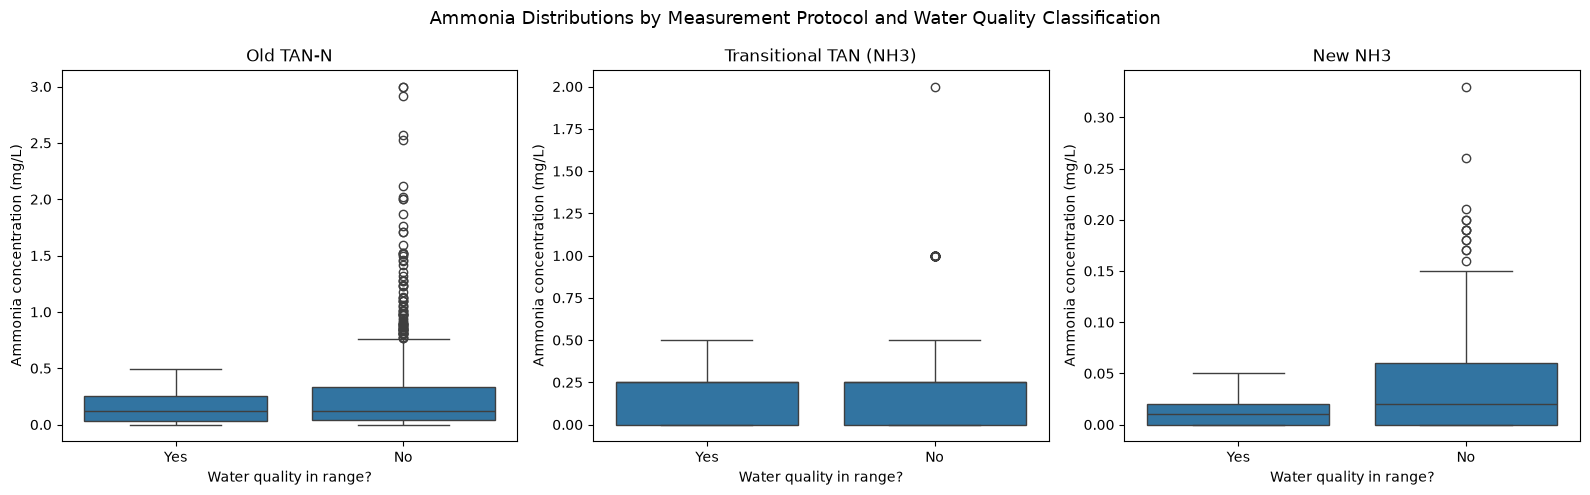

In [91]:
# CELL 62: AMMONIA DISTRIBUTIONS BY PROTOCOL AND CLASSIFICATION

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create the figures directory if it does not exist
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

ammonia_protocols = {
    "Old TAN-N": "Ammonia—TAN (NH3-N) (mg/L)",
    "Transitional TAN (NH3)": "Ammonia—TAN (NH3) (mg/L)",
    "New NH3": "Ammonia—NH3 (mg/L)"
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (protocol, column) in zip(axes, ammonia_protocols.items()):

    plot_data = df.loc[
        df[column].notna(),
        [column, "Is WQ in range?"]
    ].copy()

    sns.boxplot(
        data=plot_data,
        x="Is WQ in range?",
        y=column,
        order=["Yes", "No"],
        ax=ax
    )

    ax.set_title(protocol)
    ax.set_xlabel("Water quality in range?")
    ax.set_ylabel("Ammonia concentration (mg/L)")

fig.suptitle(
    "Ammonia Distributions by Measurement Protocol and Water Quality Classification",
    fontsize=13
)

plt.tight_layout()

# Export the figure
figure_path = (
    figures_dir / "02_ammonia_distributions_by_protocol_and_classification.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("FIGURE EXPORTED SUCCESSFULLY")
print(figure_path)

plt.show()

In [61]:
# CELL 63: AMMONIA DISTRIBUTION BY REGION AND OBSERVATION TYPE

ammonia_protocols = {
    "Old TAN-N": "Ammonia—TAN (NH3-N) (mg/L)",
    "Transitional TAN (NH3)": "Ammonia—TAN (NH3) (mg/L)",
    "New NH3": "Ammonia—NH3 (mg/L)"
}

results = []

for protocol, column in ammonia_protocols.items():

    protocol_data = df.loc[
        df[column].notna(),
        [column, "region", "Type", "Is WQ in range?"]
    ]

    grouped = (
        protocol_data
        .groupby(
            ["region", "Type", "Is WQ in range?"],
            observed=True
        )[column]
        .agg(
            record_count="count",
            mean="mean",
            median="median",
            minimum="min",
            maximum="max"
        )
        .reset_index()
    )

    grouped.insert(0, "Ammonia protocol", protocol)
    results.append(grouped)

ammonia_regional_type_comparison = pd.concat(
    results,
    ignore_index=True
)

numeric_columns = ["mean", "median", "minimum", "maximum"]

ammonia_regional_type_comparison[numeric_columns] = (
    ammonia_regional_type_comparison[numeric_columns].round(3)
)

display(ammonia_regional_type_comparison)

,Ammonia protocol,region,Type,Is WQ in range?,record_count,mean,median,minimum,maximum
0,Old TAN-N,Eluru,Evening,No,139,0.422,0.33,0.0,2.00
1,Old TAN-N,Eluru,Evening,Yes,63,0.148,0.05,0.0,0.44
2,Old TAN-N,Eluru,Morning,No,687,0.283,0.20,0.0,3.00
3,Old TAN-N,Eluru,Morning,Yes,2410,0.203,0.21,0.0,0.49
4,Old TAN-N,Nellore,Evening,No,102,0.070,0.00,0.0,1.52
5,Old TAN-N,Nellore,Evening,Yes,493,0.061,0.02,0.0,0.47
6,Old TAN-N,Nellore,Morning,No,224,0.096,0.00,0.0,2.53
7,Old TAN-N,Nellore,Morning,Yes,1172,0.066,0.03,0.0,0.47
8,Transitional TAN (NH3),Eluru,Morning,No,245,0.295,0.25,0.0,2.00
9,Transitional TAN (NH3),Eluru,Morning,Yes,1414,0.142,0.25,0.0,0.50


FIGURE EXPORTED SUCCESSFULLY
..\outputs\figures\01_monthly_ammonia_trends_by_protocol.png


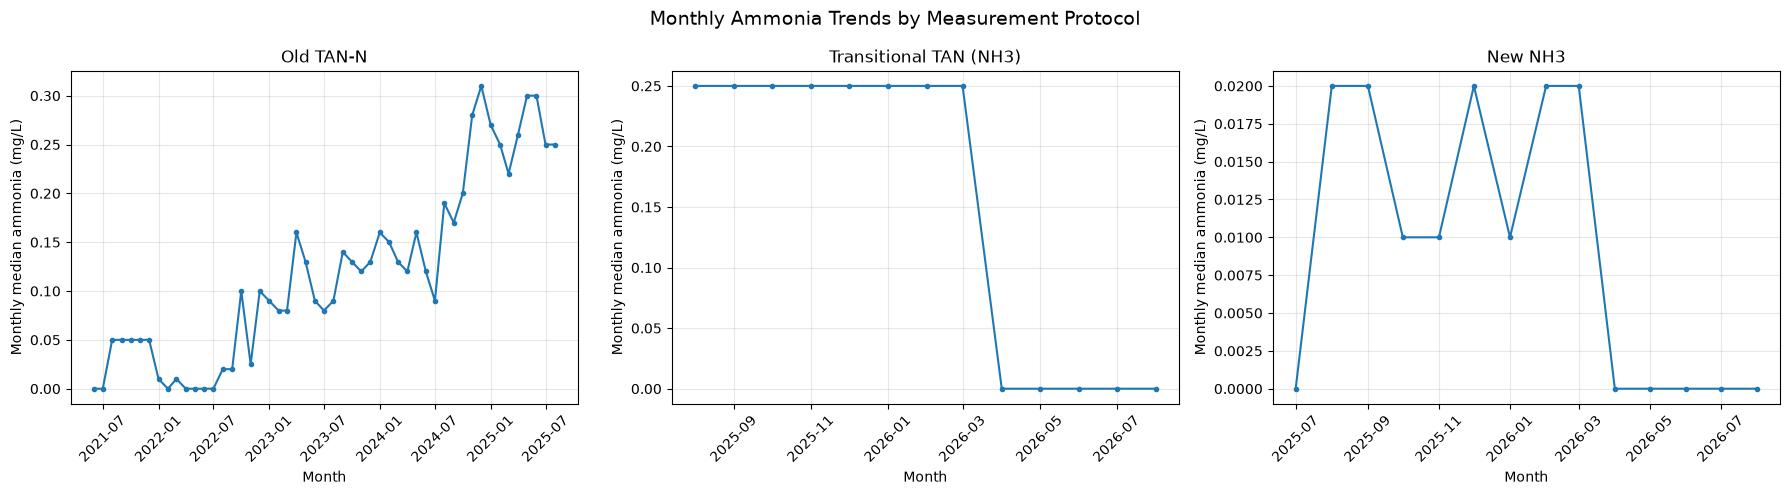

In [90]:
# CELL 64: MONTHLY AMMONIA TRENDS BY MEASUREMENT PROTOCOL

from pathlib import Path

# Create the figures directory
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

ammonia_protocols = {
    "Old TAN-N": "Ammonia—TAN (NH3-N) (mg/L)",
    "Transitional TAN (NH3)": "Ammonia—TAN (NH3) (mg/L)",
    "New NH3": "Ammonia—NH3 (mg/L)"
}

date_column = "Date of data collection"

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (protocol, column) in zip(axes, ammonia_protocols.items()):

    protocol_data = df.loc[
        df[column].notna(),
        [date_column, column]
    ].copy()

    protocol_data["Date"] = pd.to_datetime(
        protocol_data[date_column],
        format="%m/%d/%Y",
        errors="coerce"
    )

    protocol_data = protocol_data.dropna(subset=["Date"])

    protocol_data["Month"] = (
        protocol_data["Date"].dt.to_period("M").dt.to_timestamp()
    )

    monthly_summary = (
        protocol_data
        .groupby("Month")[column]
        .median()
    )

    ax.plot(
        monthly_summary.index,
        monthly_summary.values,
        marker="o",
        markersize=3
    )

    ax.set_title(protocol)
    ax.set_xlabel("Month")
    ax.set_ylabel("Monthly median ammonia (mg/L)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "Monthly Ammonia Trends by Measurement Protocol",
    fontsize=14
)

plt.tight_layout()

# Export the figure as a high-resolution PNG
figure_path = (
    figures_dir / "01_monthly_ammonia_trends_by_protocol.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("FIGURE EXPORTED SUCCESSFULLY")
print(figure_path)

plt.show()

In [63]:
# CELL 65: MONTHLY AMMONIA SAMPLE COUNTS AND ZERO-VALUE PROPORTIONS

ammonia_protocols = {
    "Old TAN-N": "Ammonia—TAN (NH3-N) (mg/L)",
    "Transitional TAN (NH3)": "Ammonia—TAN (NH3) (mg/L)",
    "New NH3": "Ammonia—NH3 (mg/L)"
}

date_column = "Date of data collection"
monthly_results = []

for protocol, column in ammonia_protocols.items():

    protocol_data = df.loc[
        df[column].notna(),
        [date_column, column]
    ].copy()

    protocol_data["Date"] = pd.to_datetime(
        protocol_data[date_column],
        format="%m/%d/%Y",
        errors="coerce"
    )

    protocol_data = protocol_data.dropna(subset=["Date"])

    protocol_data["Month"] = (
        protocol_data["Date"].dt.to_period("M").dt.to_timestamp()
    )

    monthly_summary = (
        protocol_data
        .groupby("Month")[column]
        .agg(
            sample_count="count",
            zero_count=lambda values: (values == 0).sum(),
            monthly_median="median"
        )
        .reset_index()
    )

    monthly_summary["Ammonia protocol"] = protocol

    monthly_summary["zero_percentage"] = (
        monthly_summary["zero_count"]
        / monthly_summary["sample_count"] * 100
    )

    monthly_results.append(monthly_summary)

monthly_ammonia_audit = pd.concat(
    monthly_results,
    ignore_index=True
)

monthly_ammonia_audit = monthly_ammonia_audit[
    [
        "Ammonia protocol",
        "Month",
        "sample_count",
        "zero_count",
        "zero_percentage",
        "monthly_median"
    ]
].sort_values(
    ["Ammonia protocol", "Month"]
).reset_index(drop=True)

monthly_ammonia_audit[
    ["zero_percentage", "monthly_median"]
] = monthly_ammonia_audit[
    ["zero_percentage", "monthly_median"]
].round(3)

display(monthly_ammonia_audit)

,Ammonia protocol,Month,sample_count,zero_count,zero_percentage,monthly_median
0,New NH3,2025-07-01,1,1,100.000,0.00
1,New NH3,2025-08-01,35,4,11.429,0.02
2,New NH3,2025-09-01,165,37,22.424,0.02
3,New NH3,2025-10-01,109,31,28.440,0.01
4,New NH3,2025-11-01,166,57,34.337,0.01
...,...,...,...,...,...,...
73,Transitional TAN (NH3),2026-04-01,191,110,57.592,0.00
74,Transitional TAN (NH3),2026-05-01,179,135,75.419,0.00
75,Transitional TAN (NH3),2026-06-01,117,99,84.615,0.00
76,Transitional TAN (NH3),2026-07-01,116,82,70.690,0.00


In [64]:
# CELL 66: COMPARE ZERO-VALUE AGREEMENT BETWEEN OVERLAPPING AMMONIA PROTOCOLS

transitional_col = "Ammonia—TAN (NH3) (mg/L)"
new_nh3_col = "Ammonia—NH3 (mg/L)"
date_column = "Date of data collection"

overlap_data = df.loc[
    df[transitional_col].notna()
    & df[new_nh3_col].notna(),
    [date_column, transitional_col, new_nh3_col]
].copy()

overlap_data["Date"] = pd.to_datetime(
    overlap_data[date_column],
    format="%m/%d/%Y",
    errors="coerce"
)

overlap_data = overlap_data.dropna(subset=["Date"])

overlap_data["Month"] = (
    overlap_data["Date"].dt.to_period("M").dt.to_timestamp()
)

overlap_data["Zero agreement category"] = "Both non-zero"

overlap_data.loc[
    (overlap_data[transitional_col] == 0)
    & (overlap_data[new_nh3_col] == 0),
    "Zero agreement category"
] = "Both zero"

overlap_data.loc[
    (overlap_data[transitional_col] == 0)
    & (overlap_data[new_nh3_col] != 0),
    "Zero agreement category"
] = "Transitional only zero"

overlap_data.loc[
    (overlap_data[transitional_col] != 0)
    & (overlap_data[new_nh3_col] == 0),
    "Zero agreement category"
] = "New NH3 only zero"

monthly_agreement = (
    overlap_data
    .groupby(["Month", "Zero agreement category"])
    .size()
    .unstack(fill_value=0)
)

category_columns = [
    "Both zero",
    "Both non-zero",
    "Transitional only zero",
    "New NH3 only zero"
]

monthly_agreement = monthly_agreement.reindex(
    columns=category_columns,
    fill_value=0
)

monthly_agreement["Paired sample count"] = (
    monthly_agreement[category_columns].sum(axis=1)
)

monthly_agreement["Zero-status agreement (%)"] = (
    (
        monthly_agreement["Both zero"]
        + monthly_agreement["Both non-zero"]
    )
    / monthly_agreement["Paired sample count"]
    * 100
).round(2)

display(monthly_agreement.reset_index())

Zero agreement category,Month,Both zero,Both non-zero,Transitional only zero,New NH3 only zero,Paired sample count,Zero-status agreement (%)
0,2025-08-01,4,29,2,0,35,94.29
1,2025-09-01,37,128,0,0,165,100.00
2,2025-10-01,30,78,0,1,109,99.08
3,2025-11-01,57,109,0,0,166,100.00
4,2025-12-01,26,121,0,0,147,100.00
5,2026-01-01,18,57,0,0,75,100.00
6,2026-02-01,54,91,0,0,145,100.00
7,2026-03-01,82,120,0,0,202,100.00
8,2026-04-01,107,81,3,0,191,98.43
9,2026-05-01,135,44,0,0,179,100.00


In [65]:
# CELL 67: NUMERICAL COMPARISON OF OVERLAPPING AMMONIA MEASUREMENTS

transitional_col = "Ammonia—TAN (NH3) (mg/L)"
new_nh3_col = "Ammonia—NH3 (mg/L)"
date_column = "Date of data collection"

paired_data = df.loc[
    df[transitional_col].notna()
    & df[new_nh3_col].notna(),
    [date_column, transitional_col, new_nh3_col]
].copy()

paired_data["Date"] = pd.to_datetime(
    paired_data[date_column],
    format="%m/%d/%Y",
    errors="coerce"
)

paired_data = paired_data.dropna(subset=["Date"])

paired_data["Month"] = (
    paired_data["Date"].dt.to_period("M").dt.to_timestamp()
)

paired_data["Absolute difference"] = (
    paired_data[transitional_col] - paired_data[new_nh3_col]
).abs()

monthly_numeric_comparison = (
    paired_data
    .groupby("Month")
    .agg(
        paired_sample_count=(transitional_col, "count"),
        transitional_median=(transitional_col, "median"),
        new_nh3_median=(new_nh3_col, "median"),
        mean_absolute_difference=("Absolute difference", "mean"),
        median_absolute_difference=("Absolute difference", "median"),
        exact_numeric_matches=("Absolute difference", lambda x: (x == 0).sum())
    )
    .reset_index()
)

numeric_columns = [
    "transitional_median",
    "new_nh3_median",
    "mean_absolute_difference",
    "median_absolute_difference"
]

monthly_numeric_comparison[numeric_columns] = (
    monthly_numeric_comparison[numeric_columns].round(4)
)

display(monthly_numeric_comparison)

,Month,paired_sample_count,transitional_median,new_nh3_median,mean_absolute_difference,median_absolute_difference,exact_numeric_matches
0,2025-08-01,35,0.25,0.02,0.1911,0.22,4
1,2025-09-01,165,0.25,0.02,0.1872,0.22,37
2,2025-10-01,109,0.25,0.01,0.1880,0.23,30
3,2025-11-01,166,0.25,0.01,0.1842,0.23,57
4,2025-12-01,147,0.25,0.02,0.2333,0.23,26
5,2026-01-01,75,0.25,0.01,0.2073,0.23,18
6,2026-02-01,145,0.25,0.02,0.1786,0.22,54
7,2026-03-01,202,0.25,0.02,0.1865,0.22,82
8,2026-04-01,191,0.00,0.00,0.1112,0.00,107
9,2026-05-01,179,0.00,0.00,0.0575,0.00,135


In [66]:
# CELL 68: INSPECT PAIRED AMMONIA MEASUREMENTS AROUND APRIL 2026

transitional_col = "Ammonia—TAN (NH3) (mg/L)"
new_nh3_col = "Ammonia—NH3 (mg/L)"
date_column = "Date of data collection"

transition_records = df.loc[
    df[transitional_col].notna()
    & df[new_nh3_col].notna(),
    [
        "pond_id",
        date_column,
        "region",
        "Type",
        transitional_col,
        new_nh3_col
    ]
].copy()

transition_records["Date"] = pd.to_datetime(
    transition_records[date_column],
    format="%m/%d/%Y",
    errors="coerce"
)

transition_records = transition_records.loc[
    transition_records["Date"].between(
        "2026-03-01",
        "2026-04-30"
    )
].copy()

transition_records["Absolute difference"] = (
    transition_records[transitional_col]
    - transition_records[new_nh3_col]
).abs()

transition_records = transition_records[
    [
        "pond_id",
        date_column,
        "region",
        "Type",
        transitional_col,
        new_nh3_col,
        "Absolute difference"
    ]
].sort_values(
    by=[date_column, "pond_id"]
).reset_index(drop=True)

display(transition_records)

,pond_id,Date of data collection,region,Type,Ammonia—TAN (NH3) (mg/L),Ammonia—NH3 (mg/L),Absolute difference
0,ara2_27f8f56a,03/02/2026,Eluru,Morning,0.00,0.00,0.00
1,ara2_29660d32,03/02/2026,Eluru,Morning,0.50,0.08,0.42
2,ara2_3c5dafd2,03/02/2026,Eluru,Morning,0.25,0.02,0.23
3,ara2_51ffa437,03/02/2026,Eluru,Morning,0.00,0.00,0.00
4,ara2_55de7689,03/02/2026,Eluru,Morning,0.00,0.00,0.00
...,...,...,...,...,...,...,...
388,ara2_249e0180,04/29/2026,Eluru,Morning,0.00,0.00,0.00
389,ara2_d891f276,04/29/2026,Eluru,Morning,0.25,0.03,0.22
390,ara2_09faa72c,04/30/2026,Eluru,Morning,0.25,0.03,0.22
391,ara2_249e0180,04/30/2026,Eluru,Morning,0.00,0.00,0.00


In [67]:
# CELL 69: DAILY PAIRED AMMONIA COMPARISON

transitional_col = "Ammonia—TAN (NH3) (mg/L)"
new_nh3_col = "Ammonia—NH3 (mg/L)"
date_column = "Date of data collection"

daily_data = df.loc[
    df[transitional_col].notna()
    & df[new_nh3_col].notna(),
    [date_column, transitional_col, new_nh3_col]
].copy()

daily_data["Date"] = pd.to_datetime(
    daily_data[date_column],
    format="%m/%d/%Y",
    errors="coerce"
)

daily_data = daily_data.loc[
    daily_data["Date"].between("2026-03-01", "2026-04-30")
].copy()

daily_data["Absolute difference"] = (
    daily_data[transitional_col] - daily_data[new_nh3_col]
).abs()

daily_data["Exact match"] = (
    daily_data[transitional_col] == daily_data[new_nh3_col]
)

daily_data["Both zero"] = (
    (daily_data[transitional_col] == 0)
    & (daily_data[new_nh3_col] == 0)
)

daily_comparison = (
    daily_data.groupby("Date")
    .agg(
        Paired_records=(transitional_col, "count"),
        TAN_median=(transitional_col, "median"),
        NH3_median=(new_nh3_col, "median"),
        Median_absolute_difference=("Absolute difference", "median"),
        Mean_absolute_difference=("Absolute difference", "mean"),
        Exact_matches=("Exact match", "sum"),
        Both_zero_records=("Both zero", "sum")
    )
    .reset_index()
)

daily_comparison["Exact_match_%"] = (
    daily_comparison["Exact_matches"]
    / daily_comparison["Paired_records"] * 100
).round(2)

daily_comparison["Both_zero_%"] = (
    daily_comparison["Both_zero_records"]
    / daily_comparison["Paired_records"] * 100
).round(2)

display(daily_comparison.round(4))

C:\Users\hymar\AppData\Local\Temp\ipykernel_24204\369425924.py:60: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(daily_comparison.round(4))


,Date,Paired_records,TAN_median,NH3_median,Median_absolute_difference,Mean_absolute_difference,Exact_matches,Both_zero_records,Exact_match_%,Both_zero_%
0,2026-03-02,11,0.000,0.000,0.000,0.1018,7,7,63.64,63.64
1,2026-03-03,5,0.000,0.000,0.000,0.0440,4,4,80.00,80.00
2,2026-03-04,3,0.250,0.030,0.220,0.2233,1,1,33.33,33.33
3,2026-03-05,10,0.250,0.020,0.230,0.2070,2,2,20.00,20.00
4,2026-03-06,9,0.250,0.030,0.220,0.2456,0,0,0.00,0.00
5,2026-03-08,3,0.250,0.010,0.240,0.3000,0,0,0.00,0.00
6,2026-03-09,12,0.250,0.025,0.220,0.2858,5,5,41.67,41.67
7,2026-03-10,13,0.000,0.000,0.000,0.0885,9,9,69.23,69.23
8,2026-03-11,12,0.125,0.010,0.115,0.2883,6,6,50.00,50.00
9,2026-03-12,14,0.000,0.000,0.000,0.2636,8,8,57.14,57.14


In [68]:
# CELL 70: FREQUENCY OF PAIRED AMMONIA VALUE COMBINATIONS

transitional_col = "Ammonia—TAN (NH3) (mg/L)"
new_nh3_col = "Ammonia—NH3 (mg/L)"
date_column = "Date of data collection"

paired_values = df.loc[
    df[transitional_col].notna()
    & df[new_nh3_col].notna(),
    [date_column, transitional_col, new_nh3_col]
].copy()

paired_values["Date"] = pd.to_datetime(
    paired_values[date_column],
    format="%m/%d/%Y",
    errors="coerce"
)

paired_values = paired_values.loc[
    paired_values["Date"].between("2026-03-01", "2026-04-30")
].copy()

pair_frequency = (
    paired_values
    .groupby([transitional_col, new_nh3_col])
    .size()
    .reset_index(name="Record_count")
    .sort_values("Record_count", ascending=False)
    .reset_index(drop=True)
)

pair_frequency["Percentage"] = (
    pair_frequency["Record_count"]
    / pair_frequency["Record_count"].sum() * 100
).round(2)

display(pair_frequency)

,Ammonia—TAN (NH3) (mg/L),Ammonia—NH3 (mg/L),Record_count,Percentage
0,0.00,0.00,189,48.09
1,0.25,0.03,83,21.12
2,0.25,0.02,54,13.74
3,0.50,0.04,10,2.54
4,0.25,0.01,10,2.54
5,0.50,0.05,6,1.53
6,0.25,0.04,6,1.53
7,0.25,0.05,6,1.53
8,0.25,0.06,5,1.27
9,0.50,0.03,5,1.27


In [69]:
# CELL 71: VERIFY TEMPERATURE-RELATED COLUMN NAMES

temperature_columns = [
    column
    for column in df.columns
    if "temp" in column.lower()
]

temperature_audit = pd.DataFrame({
    "Temperature-related column": temperature_columns
})

display(temperature_audit)

,Temperature-related column
0,Temp (in °C)


In [70]:
# CELL 72: PREPARE PAIRED AMMONIA AND WATER CONDITION DATA

transitional_col = "Ammonia—TAN (NH3) (mg/L)"
new_nh3_col = "Ammonia—NH3 (mg/L)"
temperature_col = "Temp (in °C)"
date_column = "Date of data collection"

paired_conditions = df.loc[
    df[transitional_col].notna()
    & df[new_nh3_col].notna(),
    [
        "pond_id",
        date_column,
        "region",
        "Type",
        "pH",
        temperature_col,
        transitional_col,
        new_nh3_col
    ]
].copy()

paired_conditions["Date"] = pd.to_datetime(
    paired_conditions[date_column],
    format="%m/%d/%Y",
    errors="coerce"
)

paired_conditions = paired_conditions.loc[
    paired_conditions["Date"].between(
        "2026-03-01",
        "2026-04-30"
    )
].copy()

paired_conditions["Complete_measurements"] = (
    paired_conditions[
        [
            "pH",
            temperature_col,
            transitional_col,
            new_nh3_col
        ]
    ].notna().all(axis=1)
)

condition_summary = pd.DataFrame({
    "Measure": [
        "Total paired records",
        "Records with pH available",
        "Records with temperature available",
        "Records with all four measurements",
        "Records missing at least one required measurement"
    ],
    "Count": [
        len(paired_conditions),
        paired_conditions["pH"].notna().sum(),
        paired_conditions[temperature_col].notna().sum(),
        paired_conditions["Complete_measurements"].sum(),
        (~paired_conditions["Complete_measurements"]).sum()
    ]
})

display(condition_summary)

,Measure,Count
0,Total paired records,393
1,Records with pH available,393
2,Records with temperature available,393
3,Records with all four measurements,393
4,Records missing at least one required measurement,0


In [71]:
# CELL 73: COMPARE OBSERVED NH3 WITH THEORETICAL NH3

transitional_col = "Ammonia—TAN (NH3) (mg/L)"
new_nh3_col = "Ammonia—NH3 (mg/L)"
temperature_col = "Temp (in °C)"

chemistry_data = paired_conditions.copy()

# Convert water temperature to Kelvin
temperature_kelvin = chemistry_data[temperature_col] + 273.15

# Calculate ammonia pKa using the freshwater equilibrium relationship
pKa = 0.09018 + (2729.92 / temperature_kelvin)

# Calculate the unionised NH3 fraction
chemistry_data["NH3_fraction"] = (
    1 / (1 + 10 ** (pKa - chemistry_data["pH"]))
)

# Estimate unionised NH3 from the recorded TAN concentration
chemistry_data["Expected_NH3"] = (
    chemistry_data[transitional_col]
    * chemistry_data["NH3_fraction"]
)

# Compare expected and recorded NH3
chemistry_data["Absolute_error"] = (
    chemistry_data["Expected_NH3"]
    - chemistry_data[new_nh3_col]
).abs()

chemistry_data["Signed_error"] = (
    chemistry_data[new_nh3_col]
    - chemistry_data["Expected_NH3"]
)

chemistry_summary = pd.DataFrame({
    "Metric": [
        "Paired records",
        "Median recorded TAN",
        "Median recorded NH3",
        "Median expected NH3",
        "Mean absolute difference: expected vs recorded NH3",
        "Median absolute difference: expected vs recorded NH3",
        "Mean signed difference: recorded minus expected NH3",
        "Median pH",
        "Median temperature (°C)"
    ],
    "Value": [
        len(chemistry_data),
        chemistry_data[transitional_col].median(),
        chemistry_data[new_nh3_col].median(),
        chemistry_data["Expected_NH3"].median(),
        chemistry_data["Absolute_error"].mean(),
        chemistry_data["Absolute_error"].median(),
        chemistry_data["Signed_error"].mean(),
        chemistry_data["pH"].median(),
        chemistry_data[temperature_col].median()
    ]
})

display(chemistry_summary.round(5))

,Metric,Value
0,Paired records,393.00000
1,Median recorded TAN,0.25000
2,Median recorded NH3,0.01000
3,Median expected NH3,0.01274
4,Mean absolute difference: expected vs recorded...,0.00146
5,Median absolute difference: expected vs record...,0.00018
6,Mean signed difference: recorded minus expecte...,0.00002
7,Median pH,8.20000
8,Median temperature (°C),29.10000


In [72]:
# CELL 74: STATISTICAL AGREEMENT OF EXPECTED AND RECORDED NH3

observed = chemistry_data[new_nh3_col]
expected = chemistry_data["Expected_NH3"]

valid = observed.notna() & expected.notna()

observed = observed.loc[valid]
expected = expected.loc[valid]

difference = observed - expected

agreement_results = pd.DataFrame({
    "Metric": [
        "Valid paired records",
        "Pearson correlation",
        "Spearman correlation",
        "Coefficient of determination (R²)",
        "Mean absolute error (mg/L)",
        "Root mean squared error (mg/L)",
        "Mean signed error (mg/L)",
        "Exact numerical matches",
        "Exact numerical matches (%)"
    ],
    "Value": [
        len(observed),
        observed.corr(expected, method="pearson"),
        observed.corr(expected, method="spearman"),
        1 - (
            ((observed - expected) ** 2).sum()
            / ((observed - observed.mean()) ** 2).sum()
        ),
        difference.abs().mean(),
        (difference.pow(2).mean()) ** 0.5,
        difference.mean(),
        (observed == expected).sum(),
        (observed == expected).mean() * 100
    ]
})

display(agreement_results.round(6))

,Metric,Value
0,Valid paired records,393.000000
1,Pearson correlation,0.994173
2,Spearman correlation,0.986429
3,Coefficient of determination (R²),0.988234
4,Mean absolute error (mg/L),0.001464
5,Root mean squared error (mg/L),0.002629
6,Mean signed error (mg/L),0.000018
7,Exact numerical matches,189.000000
8,Exact numerical matches (%),48.091603


In [73]:
# CELL 75: TEST NH3 AGREEMENT AFTER TWO-DECIMAL ROUNDING

observed = chemistry_data[new_nh3_col]
expected = chemistry_data["Expected_NH3"]

valid = observed.notna() & expected.notna()

rounding_test = pd.DataFrame({
    "Observed_NH3": observed.loc[valid],
    "Expected_NH3": expected.loc[valid]
})

rounding_test["Expected_NH3_rounded"] = (
    rounding_test["Expected_NH3"].round(2)
)

rounding_test["Matches_after_rounding"] = (
    rounding_test["Observed_NH3"]
    == rounding_test["Expected_NH3_rounded"]
)

rounding_summary = pd.DataFrame({
    "Metric": [
        "Valid paired records",
        "Matches after rounding expected NH3 to 2 decimals",
        "Matches after rounding (%)",
        "Non-matches after rounding",
        "Non-matches after rounding (%)"
    ],
    "Value": [
        len(rounding_test),
        rounding_test["Matches_after_rounding"].sum(),
        rounding_test["Matches_after_rounding"].mean() * 100,
        (~rounding_test["Matches_after_rounding"]).sum(),
        (~rounding_test["Matches_after_rounding"]).mean() * 100
    ]
})

display(rounding_summary.round(4))

,Metric,Value
0,Valid paired records,393.0000
1,Matches after rounding expected NH3 to 2 decimals,384.0000
2,Matches after rounding (%),97.7099
3,Non-matches after rounding,9.0000
4,Non-matches after rounding (%),2.2901


In [74]:
# CELL 76: INSPECT NH3 ROUNDING EXCEPTIONS

rounding_exceptions = rounding_test.loc[
    ~rounding_test["Matches_after_rounding"]
].copy()

rounding_exceptions["Difference"] = (
    rounding_exceptions["Observed_NH3"]
    - rounding_exceptions["Expected_NH3"]
)

exception_summary = rounding_exceptions[
    [
        "Observed_NH3",
        "Expected_NH3",
        "Expected_NH3_rounded",
        "Difference"
    ]
].sort_values(
    by="Difference",
    key=lambda values: values.abs(),
    ascending=False
).reset_index(drop=True)

display(exception_summary.round(6))

,Observed_NH3,Expected_NH3,Expected_NH3_rounded,Difference
0,0.02,0.000000,0.00,0.020000
1,0.02,0.000000,0.00,0.020000
2,0.01,0.000000,0.00,0.010000
3,0.02,0.027649,0.03,-0.007649
4,0.03,0.035285,0.04,-0.005285
5,0.04,0.045149,0.05,-0.005149
6,0.02,0.025057,0.03,-0.005057
7,0.02,0.025053,0.03,-0.005053
8,0.16,0.165019,0.17,-0.005019


In [75]:
# CELL 77: INSPECT COMPLETE AMMONIA ROUNDING EXCEPTION RECORDS

exception_records = chemistry_data.loc[
    rounding_exceptions.index,
    [
        "pond_id",
        "Date",
        "pH",
        temperature_col,
        transitional_col,
        new_nh3_col,
        "NH3_fraction",
        "Expected_NH3",
        "Absolute_error"
    ]
].copy()

exception_records = exception_records.sort_values(
    by=["Date", "pond_id"]
).reset_index(drop=True)

display(exception_records.round(6))

C:\Users\hymar\AppData\Local\Temp\ipykernel_24204\3984688170.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(exception_records.round(6))


,pond_id,Date,pH,Temp (in °C),Ammonia—TAN (NH3) (mg/L),Ammonia—NH3 (mg/L),NH3_fraction,Expected_NH3,Absolute_error
0,ara2_176528d3,2026-03-24,8.19,28.4,0.25,0.02,0.100229,0.025057,0.005057
1,ara2_f17bbe2f,2026-03-25,8.43,28.7,1.00,0.16,0.165019,0.165019,0.005019
2,ara2_ef01d63e,2026-04-01,8.11,29.4,0.50,0.04,0.090299,0.045149,0.005149
3,ara2_00793177,2026-04-08,8.32,29.7,0.25,0.03,0.141138,0.035285,0.005285
4,ara2_bdf1f578,2026-04-09,8.16,29.4,0.25,0.02,0.100213,0.025053,0.005053
5,ara2_6857ac3f,2026-04-15,8.19,30.0,0.25,0.02,0.110596,0.027649,0.007649
6,ara2_8cf52ce5,2026-04-15,8.18,29.7,0.00,0.02,0.106383,0.000000,0.020000
7,ara2_970ce848,2026-04-21,8.29,30.2,0.00,0.02,0.136964,0.000000,0.020000
8,ara2_84b6fb93,2026-04-22,8.21,30.2,0.00,0.01,0.116609,0.000000,0.010000


In [76]:
# CELL 78: TEST WHETHER NH3 VALUES WERE TRUNCATED TO TWO DECIMALS

observed = chemistry_data[new_nh3_col]
expected = chemistry_data["Expected_NH3"]

valid = observed.notna() & expected.notna()

truncation_test = pd.DataFrame({
    "Observed_NH3": observed.loc[valid],
    "Expected_NH3": expected.loc[valid]
})

truncation_test["Expected_NH3_truncated"] = (
    (truncation_test["Expected_NH3"] * 100)
    .astype(int) / 100
)

truncation_test["Matches_after_truncation"] = (
    truncation_test["Observed_NH3"]
    == truncation_test["Expected_NH3_truncated"]
)

truncation_summary = pd.DataFrame({
    "Metric": [
        "Valid paired records",
        "Matches after truncation to 2 decimals",
        "Matches after truncation (%)",
        "Non-matches after truncation",
        "Non-matches after truncation (%)"
    ],
    "Value": [
        len(truncation_test),
        truncation_test["Matches_after_truncation"].sum(),
        truncation_test["Matches_after_truncation"].mean() * 100,
        (~truncation_test["Matches_after_truncation"]).sum(),
        (~truncation_test["Matches_after_truncation"]).mean() * 100
    ]
})

display(truncation_summary.round(4))

,Metric,Value
0,Valid paired records,393.0000
1,Matches after truncation to 2 decimals,293.0000
2,Matches after truncation (%),74.5547
3,Non-matches after truncation,100.0000
4,Non-matches after truncation (%),25.4453


In [77]:
# CELL 79: COMPARE ROUNDING AND TRUNCATION AGREEMENT

comparison = truncation_test.copy()

comparison["Expected_NH3_rounded"] = (
    comparison["Expected_NH3"].round(2)
)

comparison["Matches_rounding"] = (
    comparison["Observed_NH3"]
    == comparison["Expected_NH3_rounded"]
)

comparison["Matches_truncation"] = (
    comparison["Observed_NH3"]
    == comparison["Expected_NH3_truncated"]
)

comparison["Agreement_category"] = "Matches neither"

comparison.loc[
    comparison["Matches_rounding"] & comparison["Matches_truncation"],
    "Agreement_category"
] = "Matches both"

comparison.loc[
    comparison["Matches_rounding"] & ~comparison["Matches_truncation"],
    "Agreement_category"
] = "Rounding only"

comparison.loc[
    ~comparison["Matches_rounding"] & comparison["Matches_truncation"],
    "Agreement_category"
] = "Truncation only"

agreement_summary = (
    comparison["Agreement_category"]
    .value_counts()
    .rename_axis("Agreement category")
    .reset_index(name="Record count")
)

agreement_summary["Percentage"] = (
    agreement_summary["Record count"]
    / len(comparison) * 100
)

display(agreement_summary.round(2))

,Agreement category,Record count,Percentage
0,Matches both,287,73.03
1,Rounding only,97,24.68
2,Truncation only,6,1.53
3,Matches neither,3,0.76


In [78]:
# CELL 80: INSPECT RECORDS THAT MATCH NEITHER ROUNDING NOR TRUNCATION

unexplained_records = comparison.loc[
    comparison["Agreement_category"] == "Matches neither"
].copy()

unexplained_records["pond_id"] = chemistry_data.loc[
    unexplained_records.index, "pond_id"
]

unexplained_records["Date"] = chemistry_data.loc[
    unexplained_records.index, "Date"
]

unexplained_records["pH"] = chemistry_data.loc[
    unexplained_records.index, "pH"
]

unexplained_records[temperature_col] = chemistry_data.loc[
    unexplained_records.index, temperature_col
]

unexplained_records[transitional_col] = chemistry_data.loc[
    unexplained_records.index, transitional_col
]

display(
    unexplained_records[
        [
            "pond_id",
            "Date",
            "pH",
            temperature_col,
            transitional_col,
            "Expected_NH3",
            "Observed_NH3"
        ]
    ].reset_index(drop=True).round(6)
)

C:\Users\hymar\AppData\Local\Temp\ipykernel_24204\588270103.py:38: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].reset_index(drop=True).round(6)


,pond_id,Date,pH,Temp (in °C),Ammonia—TAN (NH3) (mg/L),Expected_NH3,Observed_NH3
0,ara2_84b6fb93,2026-04-22,8.21,30.2,0.0,0.0,0.01
1,ara2_970ce848,2026-04-21,8.29,30.2,0.0,0.0,0.02
2,ara2_8cf52ce5,2026-04-15,8.18,29.7,0.0,0.0,0.02


In [79]:
# CELL 81: VERIFY TDS AND STOCKING-DENSITY COLUMNS

quality_columns = [
    {
        "Column": col,
        "Non-missing records": df[col].notna().sum(),
        "Missing records": df[col].isna().sum(),
        "Unique values": df[col].nunique()
    }
    for col in df.columns
    if any(
        term in col.lower()
        for term in ["tds", "stocking", "density"]
    )
]

quality_column_audit = pd.DataFrame(quality_columns)

display(quality_column_audit)

,Column,Non-missing records,Missing records,Unique values
0,TDS (ppt),4582,7849,1017
1,Stocking density (per acre),9780,2651,564


In [80]:
# CELL 82: NUMERICAL DISTRIBUTION OF TDS AND STOCKING DENSITY

variables = [
    "TDS (ppt)",
    "Stocking density (per acre)"
]

distribution_rows = []

for column in variables:
    values = pd.to_numeric(df[column], errors="coerce").dropna()

    distribution_rows.append({
        "Variable": column,
        "Valid records": len(values),
        "Zero values": (values == 0).sum(),
        "Negative values": (values < 0).sum(),
        "Minimum": values.min(),
        "1st percentile": values.quantile(0.01),
        "25th percentile": values.quantile(0.25),
        "Median": values.median(),
        "75th percentile": values.quantile(0.75),
        "99th percentile": values.quantile(0.99),
        "Maximum": values.max(),
        "Unique values": values.nunique()
    })

distribution_audit = pd.DataFrame(distribution_rows)

display(distribution_audit.round(3))

,Variable,Valid records,Zero values,Negative values,Minimum,1st percentile,25th percentile,Median,75th percentile,99th percentile,Maximum,Unique values
0,TDS (ppt),4582,0,0,0.01,0.28,0.89,1.18,1.92,8.64,936.0,1017
1,Stocking density (per acre),9780,5,0,0.00,900.00,2285.00,2791.00,5059.00,133333.00,235294.0,564


In [81]:
# CELL 83: INSPECT EXTREME TDS AND STOCKING-DENSITY RECORDS

tds_extreme = df[
    pd.to_numeric(df["TDS (ppt)"], errors="coerce") > 50
].copy()

stocking_extreme = df[
    pd.to_numeric(
        df["Stocking density (per acre)"],
        errors="coerce"
    ) >= 100000
].copy()

tds_extreme["Investigation variable"] = "TDS (ppt)"
tds_extreme["Recorded value"] = pd.to_numeric(
    tds_extreme["TDS (ppt)"],
    errors="coerce"
)

stocking_extreme["Investigation variable"] = (
    "Stocking density (per acre)"
)
stocking_extreme["Recorded value"] = pd.to_numeric(
    stocking_extreme["Stocking density (per acre)"],
    errors="coerce"
)

inspection_columns = [
    "Investigation variable",
    "pond_id",
    "region",
    "Date of data collection",
    "Type",
    "Recorded value"
]

extreme_records = pd.concat(
    [
        tds_extreme[inspection_columns],
        stocking_extreme[inspection_columns]
    ],
    ignore_index=True
)

display(
    extreme_records.sort_values(
        ["Investigation variable", "Recorded value"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

,Investigation variable,pond_id,region,Date of data collection,Type,Recorded value
0,Stocking density (per acre),ara2_7bd7da7f,Eluru,05/27/2025,Evening,235294.0
1,Stocking density (per acre),ara2_7bd7da7f,Eluru,05/27/2025,Morning,235294.0
2,Stocking density (per acre),ara2_8cf52ce5,Eluru,07/10/2026,Evening,200000.0
3,Stocking density (per acre),ara2_8cf52ce5,Eluru,07/10/2026,Morning,200000.0
4,Stocking density (per acre),ara2_8cf52ce5,Eluru,06/16/2026,Morning,200000.0
...,...,...,...,...,...,...
163,TDS (ppt),ara2_bd32b7fb,Eluru,09/04/2021,Evening,69.8
164,TDS (ppt),ara2_7ed0eacc,Nellore,12/26/2023,Evening,67.0
165,TDS (ppt),ara2_b77a0d03,Nellore,11/26/2023,Morning,63.0
166,TDS (ppt),ara2_44e030ef,Nellore,11/28/2023,Morning,56.0


In [82]:
# CELL 84: SUMMARISE EXTREME TDS AND STOCKING-DENSITY RECORDS

extreme_definitions = {
    "TDS (ppt)": {
        "column": "TDS (ppt)",
        "threshold": 50
    },
    "Stocking density (per acre)": {
        "column": "Stocking density (per acre)",
        "threshold": 100000
    }
}

summary_rows = []

for variable, details in extreme_definitions.items():

    column = details["column"]
    threshold = details["threshold"]

    subset = df[
        pd.to_numeric(df[column], errors="coerce") > (
            threshold if variable == "TDS (ppt)" else threshold - 1
        )
    ].copy()

    subset["Numeric value"] = pd.to_numeric(
        subset[column],
        errors="coerce"
    )

    pond_date_groups = subset.groupby(
        ["pond_id", "Date of data collection"]
    )

    repeated_groups = pond_date_groups.filter(
        lambda group: len(group) > 1
    )

    summary_rows.append({
        "Variable": variable,
        "Threshold": threshold,
        "Extreme records": len(subset),
        "Distinct ponds": subset["pond_id"].nunique(),
        "Distinct pond-date combinations": (
            subset[["pond_id", "Date of data collection"]]
            .drop_duplicates()
            .shape[0]
        ),
        "Pond-date groups with multiple records": (
            repeated_groups[
                ["pond_id", "Date of data collection"]
            ].drop_duplicates().shape[0]
        ),
        "Distinct recorded values": subset["Numeric value"].nunique(),
        "Maximum": subset["Numeric value"].max()
    })

extreme_pattern_summary = pd.DataFrame(summary_rows)

display(extreme_pattern_summary)

,Variable,Threshold,Extreme records,Distinct ponds,Distinct pond-date combinations,Pond-date groups with multiple records,Distinct recorded values,Maximum
0,TDS (ppt),50,24,18,23,1,20,936.0
1,Stocking density (per acre),100000,144,8,76,68,11,235294.0


In [83]:
# CELL 85: DETAILED INSPECTION OF EXTREME TDS RECORDS

tds_records = df[
    pd.to_numeric(df["TDS (ppt)"], errors="coerce") > 50
].copy()

tds_records["TDS (ppt)"] = pd.to_numeric(
    tds_records["TDS (ppt)"],
    errors="coerce"
)

tds_inspection = tds_records[
    [
        "pond_id",
        "region",
        "Date of data collection",
        "Type",
        "TDS (ppt)",
        "pH",
        "DO (mg/L)",
        "Temp (in °C)",
        "Is WQ in range?",
        "Parameters out of range"
    ]
].sort_values(
    "TDS (ppt)",
    ascending=False
).reset_index(drop=True)

display(tds_inspection)

,pond_id,region,Date of data collection,Type,TDS (ppt),pH,DO (mg/L),Temp (in °C),Is WQ in range?,Parameters out of range
0,ara2_20dd0295,Eluru,04/01/2022,Morning,936.0,8.43,5.0,31.2,No,Ammonia Tan Nh3N
1,ara2_bd32b7fb,Eluru,09/20/2021,Morning,923.0,7.81,2.7,32.6,No,Dissolved Oxygen
2,ara2_a2d65cb4,Eluru,10/27/2022,Morning,795.0,8.29,2.6,28.3,No,Dissolved Oxygen
3,ara2_bd32b7fb,Eluru,09/20/2021,Evening,795.0,8.12,5.7,33.3,No,Dissolved Oxygen
4,ara2_2d4cda6c,Eluru,10/17/2022,Evening,781.0,8.28,12.0,30.8,Yes,NaN
5,ara2_01463d19,Eluru,10/17/2022,Morning,781.0,7.74,2.8,28.6,No,Dissolved Oxygen
6,ara2_87661414,Eluru,10/17/2022,Evening,555.0,8.48,5.2,30.6,No,Dissolved Oxygen
7,ara2_87661414,Eluru,10/27/2022,Morning,543.0,8.27,2.7,28.8,No,Dissolved Oxygen
8,ara2_03d81c1d,Eluru,12/18/2023,Evening,155.0,8.28,9.6,28.1,Yes,NaN
9,ara2_a0d5d74d,Eluru,12/15/2023,Morning,143.0,8.26,3.1,25.5,Yes,NaN


In [84]:
# CELL 86: TDS DISTRIBUTION AND EXTREME VALUES BY EQUIPMENT

tds_data = df.copy()

tds_data["TDS (ppt)"] = pd.to_numeric(
    tds_data["TDS (ppt)"],
    errors="coerce"
)

equipment_tds_summary = (
    tds_data.dropna(subset=["TDS (ppt)", "Equipment"])
    .groupby("Equipment")
    .agg(
        Valid_TDS_records=("TDS (ppt)", "count"),
        Median_TDS=("TDS (ppt)", "median"),
        Maximum_TDS=("TDS (ppt)", "max"),
        Records_above_50=("TDS (ppt)", lambda x: (x > 50).sum()),
        Records_above_100=("TDS (ppt)", lambda x: (x > 100).sum())
    )
    .reset_index()
    .sort_values("Records_above_50", ascending=False)
)

display(equipment_tds_summary.round(3))

,Equipment,Valid_TDS_records,Median_TDS,Maximum_TDS,Records_above_50,Records_above_100
11,Taiwan #8,532,0.900,89.00,9,0
5,Taiwan #2,542,1.910,795.00,3,3
7,Taiwan #7,634,0.980,98.00,3,0
2,Taiwan,933,0.940,781.00,2,2
1,Hanna,226,1.342,936.00,2,2
12,Taiwan #9,330,2.120,143.00,1,1
6,"Taiwan #2, Winkler's Method (DO)",248,2.080,76.00,1,0
0,"Ammonia checker (Hanna), Taiwan #7",106,0.970,2.02,0,0
3,Taiwan #1,122,2.450,9.91,0,0
8,"Taiwan #7, Ammonia checker (Hanna)",1,1.320,1.32,0,0


In [85]:
# CELL 87: STOCKING-DENSITY SUMMARY BY POND

stocking_data = df.copy()

stocking_data["Stocking density (per acre)"] = pd.to_numeric(
    stocking_data["Stocking density (per acre)"],
    errors="coerce"
)

stocking_summary = (
    stocking_data.dropna(subset=["Stocking density (per acre)"])
    .groupby(["region", "pond_id"])
    .agg(
        Valid_records=("Stocking density (per acre)", "count"),
        Distinct_values=("Stocking density (per acre)", "nunique"),
        Median_density=("Stocking density (per acre)", "median"),
        Maximum_density=("Stocking density (per acre)", "max")
    )
    .reset_index()
)

stocking_summary = stocking_summary[
    stocking_summary["Maximum_density"] >= 100000
].sort_values("Maximum_density", ascending=False)

display(stocking_summary.round(2))

,region,pond_id,Valid_records,Distinct_values,Median_density,Maximum_density
132,Eluru,ara2_7bd7da7f,34,3,4706.0,235294.0
152,Eluru,ara2_8cf52ce5,46,4,18000.0,200000.0
107,Eluru,ara2_6452000e,46,4,140000.0,180000.0
84,Eluru,ara2_4441fb4f,57,5,175438.0,175438.0
62,Eluru,ara2_30c31874,19,3,119048.0,166667.0
38,Eluru,ara2_2167f891,32,2,133333.0,133333.0
116,Eluru,ara2_6ec2f0e5,57,6,11650.0,121359.0
45,Eluru,ara2_27387783,8,2,10588.0,117647.0


In [86]:
# CELL 88: TEMPORAL SUMMARY OF EXTREME STOCKING-DENSITY PONDS

stocking_data = df.copy()

stocking_data["Stocking density (per acre)"] = pd.to_numeric(
    stocking_data["Stocking density (per acre)"],
    errors="coerce"
)

stocking_data["Parsed date"] = pd.to_datetime(
    stocking_data["Date of data collection"],
    format="%m/%d/%Y",
    errors="coerce"
)

extreme_ponds = (
    stocking_data.loc[
        stocking_data["Stocking density (per acre)"] >= 100000,
        "pond_id"
    ].dropna().unique()
)

pond_history = stocking_data[
    stocking_data["pond_id"].isin(extreme_ponds)
    & stocking_data["Stocking density (per acre)"].notna()
]

temporal_summary = (
    pond_history.groupby(["region", "pond_id"])
    .agg(
        Total_records=("Stocking density (per acre)", "count"),
        Distinct_density_values=("Stocking density (per acre)", "nunique"),
        First_record=("Parsed date", "min"),
        Last_record=("Parsed date", "max"),
        Median_density=("Stocking density (per acre)", "median"),
        Maximum_density=("Stocking density (per acre)", "max")
    )
    .reset_index()
)

display(temporal_summary.round(2))

C:\Users\hymar\AppData\Local\Temp\ipykernel_24204\3430956854.py:41: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(temporal_summary.round(2))


,region,pond_id,Total_records,Distinct_density_values,First_record,Last_record,Median_density,Maximum_density
0,Eluru,ara2_2167f891,32,2,2024-12-16,2026-03-03,133333.0,133333.0
1,Eluru,ara2_27387783,8,2,2025-05-19,2026-03-11,10588.0,117647.0
2,Eluru,ara2_30c31874,19,3,2025-05-19,2026-08-03,119048.0,166667.0
3,Eluru,ara2_4441fb4f,57,5,2024-01-08,2025-06-12,175438.0,175438.0
4,Eluru,ara2_6452000e,46,4,2024-10-17,2026-06-10,140000.0,180000.0
5,Eluru,ara2_6ec2f0e5,57,6,2023-08-21,2026-07-14,11650.0,121359.0
6,Eluru,ara2_7bd7da7f,34,3,2024-04-11,2025-09-13,4706.0,235294.0
7,Eluru,ara2_8cf52ce5,46,4,2024-03-23,2026-07-10,18000.0,200000.0


In [87]:
# CELL 89: CANDIDATE PREDICTOR AVAILABILITY AND VARIATION

candidate_predictors = [
    "pH",
    "DO (mg/L)",
    "Temp (in °C)",
    "Water color",
    "Weather",
    "Type",
    "Pond status",
    "Time of data collection",
    "Equipment",
    "Ammonia—TAN (NH3-N) (mg/L)",
    "Ammonia—TAN (NH3) (mg/L)",
    "Ammonia—NH3 (mg/L)"
]

predictor_summary = pd.DataFrame({
    "Predictor": candidate_predictors,
    "Data_type": [str(df[col].dtype) for col in candidate_predictors],
    "Available_records": [df[col].notna().sum() for col in candidate_predictors],
    "Missing_records": [df[col].isna().sum() for col in candidate_predictors],
    "Availability_percent": [
        round(df[col].notna().mean() * 100, 2)
        for col in candidate_predictors
    ],
    "Distinct_values": [
        df[col].nunique(dropna=True)
        for col in candidate_predictors
    ]
})

display(predictor_summary)

,Predictor,Data_type,Available_records,Missing_records,Availability_percent,Distinct_values
0,pH,float64,12412,19,99.85,229
1,DO (mg/L),float64,12412,19,99.85,196
2,Temp (in °C),float64,12410,21,99.83,144
3,Water color,str,11572,859,93.09,6
4,Weather,str,11703,728,94.14,36
5,Type,str,12429,2,99.98,2
6,Pond status,str,12394,37,99.70,3
7,Time of data collection,str,12431,0,100.00,356
8,Equipment,str,11945,486,96.09,183
9,Ammonia—TAN (NH3-N) (mg/L),float64,5292,7139,42.57,124


In [88]:
# CELL 90: CATEGORICAL PREDICTOR VALUE FREQUENCIES

categorical_predictors = [
    "Type",
    "Pond status",
    "Water color",
    "Weather",
    "Equipment"
]

category_results = []

for column in categorical_predictors:
    counts = df[column].value_counts(dropna=False)

    for value, count in counts.head(12).items():
        category_results.append({
            "Predictor": column,
            "Category": str(value),
            "Record_count": count,
            "Percentage": round(count / len(df) * 100, 2)
        })

category_summary = pd.DataFrame(category_results)

display(category_summary)

,Predictor,Category,Record_count,Percentage
0,Type,Morning,6454,51.92
1,Type,Evening,5975,48.07
2,Type,nan,2,0.02
3,Pond status,Treatment,10741,86.40
4,Pond status,Control,1316,10.59
5,Pond status,Assessment,337,2.71
6,Pond status,nan,37,0.30
7,Water color,Dark green,5517,44.38
8,Water color,Light green,3086,24.83
9,Water color,Saturated green,1672,13.45


In [89]:
# CELL 91: PRELIMINARY PREDICTOR ELIGIBILITY REGISTER

predictor_eligibility = pd.DataFrame([
    ["pH", "Retain", "High availability; core water-quality measurement."],
    ["DO (mg/L)", "Retain", "High availability; core water-quality measurement."],
    ["Temp (in °C)", "Retain", "High availability; core water-quality measurement."],
    ["Type", "Conditional", "Morning/Evening indicator; must be known at prediction time."],
    ["Pond status", "Conditional", "Verify whether status is known before prediction and is not intervention-related leakage."],
    ["Water color", "Conditional", "Moderate missingness; investigate missingness mechanism before inclusion."],
    ["Weather", "Conditional", "Many categories; consider meaningful grouping and check missingness."],
    ["Equipment", "Exclude initially", "High cardinality and potential measurement-related confounding."],
    ["Ammonia—TAN (NH3-N) (mg/L)", "Exclude initially", "Protocol-specific and available for only part of the dataset."],
    ["Ammonia—TAN (NH3) (mg/L)", "Exclude initially", "Transitional measurement; limited availability."],
    ["Ammonia—NH3 (mg/L)", "Exclude initially", "New protocol; limited availability and not interchangeable with TAN."]
], columns=["Predictor", "Preliminary_decision", "Reason"])

display(predictor_eligibility)

,Predictor,Preliminary_decision,Reason
0,pH,Retain,High availability; core water-quality measurem...
1,DO (mg/L),Retain,High availability; core water-quality measurem...
2,Temp (in °C),Retain,High availability; core water-quality measurem...
3,Type,Conditional,Morning/Evening indicator; must be known at pr...
4,Pond status,Conditional,Verify whether status is known before predicti...
5,Water color,Conditional,Moderate missingness; investigate missingness ...
6,Weather,Conditional,Many categories; consider meaningful grouping ...
7,Equipment,Exclude initially,High cardinality and potential measurement-rel...
8,Ammonia—TAN (NH3-N) (mg/L),Exclude initially,Protocol-specific and available for only part ...
9,Ammonia—TAN (NH3) (mg/L),Exclude initially,Transitional measurement; limited availability.


## EDA Conclusions and Modelling Readiness

The exploratory data analysis identified the principal characteristics, limitations and modelling considerations of the aquaculture water-quality dataset.

### 1. Core water-quality measurements
- pH, dissolved oxygen and water temperature have greater than 99.8% data availability.
- These measurements are selected as the initial primary modelling predictors.

### 2. Conditional predictors
- Observation type, pond status, water colour and weather may provide additional information.
- Their inclusion requires consideration of prediction-time availability, missingness and potential confounding.

### 3. Measurement and reliability limitations
- Ammonia measurements follow different protocols and must remain separate.
- TDS contains extreme values requiring verification.
- Stocking density shows substantial variation within some ponds and requires verification.
- Equipment has high categorical cardinality and may introduce measurement-related variation.

### 4. Target and validation considerations
- The target classification reflects the recorded dataset criteria and should not be assumed to represent one unchanged set of thresholds across the entire study period.
- `Parameters out of range` must not be used as a predictor because it directly reveals information about the target.
- Repeated measurements from the same ponds require pond-aware validation to reduce information leakage between training and testing datasets.

### 5. Modelling direction
The initial modelling dataset will prioritise pH, dissolved oxygen and water temperature. Conditional predictors will be evaluated separately. Variables with unresolved measurement reliability or protocol limitations will be excluded from the initial primary model.

The original dataset will remain unchanged, and all exclusions and preprocessing decisions will be documented.

**EDA status: Completed.**